<a href="https://colab.research.google.com/github/BeatriceMadau/Progetto-Rosalia/blob/main/Progetto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fase 1: Estrazione Corpus

Il mio corpus di partenza è rappresentato da un corpus di testi di canzoni di Rosalia, appartenenti agli album Motomami e Lux che verrano analizzati a partire da un confronto tra dati numerici e dati qualitativi, messi poi a confronto con le recensioni dei due album. Ho selezionato trenta canzoni, quindici di Motomami e quindici di Lux, delle quali ho riportato il testo integrale, l'album di appartanenza, l'anno di uscita, la lingua, la durata e le collaborazioni.
Come primo script, ho chiesto a Python, attraverso l'LLM Gemini, di estrarre i dati contenuti nel documento del dataset realizzato manualmente su Excel.La seguente cella consente di scaricare tutti i file del progetto da GitHub.

In [15]:
# Scarica il repository GitHub con il dataset dentro la sessione di Colab
!git clone https://github.com/BeatriceMadau/Progetto-Rosalia.git

# Leggi direttamente il file CSV dalla cartella appena scaricata
import pandas as pd
df = pd.read_csv('Progetto-Rosalia/corpus canzoni(Foglio1).csv', encoding='latin-1', sep=';')

print("Dataset caricato con successo da GitHub!")

Cloning into 'Progetto-Rosalia'...
remote: Enumerating objects: 6, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 6 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (6/6), 26.03 KiB | 1.00 MiB/s, done.
Dataset caricato con successo da GitHub!


In [19]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Successivamente, ho chiesto al LLM uno script che mostrasse le prime 5 righe del dataset, come prova dell'intera comprensione del documento da parte di Python. E' comparso un ParserError. Analizzando la struttura del file, è sorto il problema che le colonne non sono separate da virgole ma da punto e virgola. Per risolverlo ho chiesto a Pandas di usare il separatore corretto.

In [5]:
import pandas as pd

# Leggiamo il file specificando il separatore a punto e virgola e la codifica
df = pd.read_csv('corpus canzoni(Foglio1).csv', encoding='latin-1', sep=';')

# Visualizziamo il numero di righe e le prime righe del dataset
print(f"✅ Dataset caricato con successo! Numero di righe e colonne: {df.shape}")
display(df.head())

✅ Dataset caricato con successo! Numero di righe e colonne: (30, 7)


,titolo,album,anno,lingue,minuti,collaborazioni,testo
0,"Sexo, Violencia y LLantas",Lux,2025,Spagnolo,02:20,no (solista),Quién pudiera vivir entre los dos\nPrimero ama...
1,Reliquia,Lux,2025,Spagnolo,03:50,no (solista),Yo que perdí mis manos en Jerez\nY mis ojos en...
2,Divinize,Lux,2025,Inglese/ Spagnolo,04:03,no (solista),Fruita roja i rodona\nQui l'endevina?\nÒbviame...
3,Porcelana,Lux,2025,Spagnolo/ Giapponese/Inglese,04:08,si (Dougie F),Mi piel es fina\nDe porcelana\nRota en la esqu...
4,Mio Cristo Piange Diamanti,Lux,2025,Italiano/Inglese,04:29,no (solista),Sei l'uragano più bello\nChe io abbia mai vist...


Per assicurarmi che funzionasse correttamente ho chiesto poi le ultime 5 righe del dataset.

In [6]:
# Visualizziamo le ultime 5 righe del dataset
display(df.tail())

,titolo,album,anno,lingue,minuti,collaborazioni,testo
25,Delirio de Grandeza,Motomami,2022,Spagnolo,02:35,no (solista),El oro pudo más que mi dolor\nNo tuviste compa...
26,CUUUUuuuuuute,Motomami,2022,Spagnolo,02:30,no (solista),"One, two, three, four, five, six, seven, eight..."
27,Como un G,Motomami,2022,Spagnolo,04:22,no (solista),"Si no lo puedes tener, lo tendrás que soltar\n..."
28,Abcdefg,Motomami,2022,Spagnolo,01:05,no (solista),"A de alfa, altura, alien\nB de bandida\nC de c..."
29,La combi Versace,Motomami,2022,Spagnolo,02:41,si (Tokischa),Juntas por la noche\nPuestas pa'l derroche\nTu...


Per testare che il codice sia stato letto correttamente, chiedo anche uno script che mostri la prima e l'ultima canzone. L'output consiste nell'anteprima dei due testi in questione.

In [9]:
# Mostra la prima canzone completa
print("=== PRIMA CANZONE ===")
for col in df.columns:
    print(f"**{col}**: {df.iloc[0][col]}")

print("\n" + "="*50 + "\n")

# Mostra l'ultima canzone completa
print("=== ULTIMA CANZONE ===")
for col in df.columns:
    print(f"**{col}**: {df.iloc[-1][col]}")

=== PRIMA CANZONE ===
**titolo**: Sexo, Violencia y LLantas
**album**: Lux
**anno**: 2025
**lingue **: Spagnolo
**minuti**: 02:20
**collaborazioni**: no (solista)
**testo**: Quién pudiera vivir entre los dos
Primero amaré el mundo y luego amaré a Dios
Quién pudiera vivir entre los dos
Primero amaré el mundo y luego amaré a Dios

Quién pudiera venir de esta tierra
Y entrar en el cielo y volver a la tierra
Que entre la tierra, la tierra y el cielo
Nunca hubiera suelo

En el primero
Sexo, violencia y llantas
Deportes de sangre, monedas en gargantas

En el segundo
Destellos, palomas y santas
La gracia y el fruto y el beso de la balanza

Quién pudiera vivir entre los dos
Primero amaré el mundo y luego amaré a Dios


=== ULTIMA CANZONE ===
**titolo**: La combi Versace
**album**: Motomami
**anno**: 2022
**lingue **: Spagnolo
**minuti**: 02:41
**collaborazioni**: si (Tokischa)
**testo**: Juntas por la noche
Puestas pa'l derroche
Tu pelo azabache
La combi Versace
Juntas por la noche
Puestas pa'

Come ulteriore prova ho chiesto l'anteprima della canzone più lunga e di quella più breve all'interno del corpus. Il risultato è stato mostrato in base alla colonna dei minuti.

In [10]:
# Troviamo l'indice della canzone con la durata maggiore nella colonna 'minuti'
# (Convertiamo la colonna in stringa per sicurezza e troviamo il valore massimo)
indice_piu_lunga = df['minuti'].astype(str).idxmax()

# Estraiamo i dettagli di quella canzone
canzone_più_lunga = df.loc[indice_piu_lunga]

print("=== LA CANZONE PIÙ LUNGA DEL CORPUS ===")
for col in df.columns:
    print(f"**{col}**: {canzone_più_lunga[col]}")

=== LA CANZONE PIÙ LUNGA DEL CORPUS ===
**titolo**: Mio Cristo Piange Diamanti
**album**: Lux
**anno**: 2025
**lingue **: Italiano/Inglese
**minuti**: 04:29
**collaborazioni**: no (solista)
**testo**: Sei l'uragano più bello
Che io abbia mai visto
Il migliore dei dolmen
Si alzerebbe per te

Fai tremare la terra
E si innalzi al tuo fianco
Ma quando a non riuscire
Ad elevarsi sei tu?
Sei tu?

Imperfetti
Agenti del caos
Ci smontiamo come i miti
Mio re dell'anarchia
Mio astro imprudente preferito
Quando piangi
Raccogli le tue lacrime
E bagna la tua fronte
Qualunque sia il crimine

Mio Cristo piange diamante
Piange, piange diamante
Mio Cristo in diamante
Ti porto, ti porto sempre
Sempre, ti porto sempre
Ti porto, ti porto sempre
Sempre, sempre

La verità è che
Entrambi abbiamo macchia
E nessuno dei due può sfuggire di l'altro
C'è sempre qualcosa di te che ancora non so
Come il lato nascosto della luna
Una volta svelato so che non lo dimenticherò

Quanti pugni ti hanno dato
Che avrebbero dov

Ho chiesto quindi, in maniera più specifica, quale fosse la canzone con il testo più lungo e quindi denso di caratteri.

In [11]:
# Creiamo una colonna temporanea con la lunghezza del testo per ciascuna canzone
df['lunghezza_testo'] = df['testo'].astype(str).str.len()

# Troviamo l'indice del valore massimo
indice_max = df['lunghezza_testo'].idxmax()
canzone_lunga = df.loc[indice_max]

print("=== LA CANZONE CON IL TESTO PIÙ LUNGO ===")
print(f"**Titolo**: {canzone_lunga['titolo']}")
print(f"**Album**: {canzone_lunga['album']}")
print(f"**Anno**: {canzone_lunga['anno']}")
print(f"**Numero di caratteri**: {canzone_lunga['lunghezza_testo']}")
print("\n--- TESTO ---")
print(canzone_lunga['testo'])

=== LA CANZONE CON IL TESTO PIÙ LUNGO ===
**Titolo**: La Rumba del Perdòn
**Album**: Lux
**Anno**: 2025
**Numero di caratteri**: 2268

--- TESTO ---
 y tu compadre
De corazón
Inseparables
Pero algo pasó

Había un quilo sin corte
En tu cajón
Y de pura envidia
Alguien te lo robó

Tu mejor amigo
El que tocaba la guitarra
¿Qué será lo que pasó?
Que de golpe la guitarra ya no sonaba
Y ni sonaba el teléfono

No sería tan amigo
Cuando aflojó las cuerdas de la guitarra
De la primera al bordón
Y ahí dentro metió el quilo
E igual que el quilo
Él también desapareció

Pero yo
Toíto te lo perdono (nonaino nonaino nonaino nonaino na)
Toíto te lo perdono (nonaino nonaino nonaino nonaino na)
Toíto te lo perdono (nonaino nonaino nonaino nonaino na)
Toíto te lo perdono (nonaino nonaino nonaino nonaino na)

Cuando dijiste "voy a bajar por tabaco"
Mirando a lo ojos a tu hijo menor
Le prometiste que en na' tu estarías de vuelta
Y nunca volviste a cruzar el umbral de la puerta por la que te fuiste

Pero
Yo 

Ho continuato ad interrogare l'LLM per assicurarmi che non ci fossero errori.

In [12]:
# Estraiamo il primo verso della prima canzone
prima_canzone_testo = str(df.iloc[0]['testo'])
# Dividiamo il testo in base alle righe (a capo) e prendiamo la prima non vuota
versi_prima = [v.strip() for v in prima_canzone_testo.split('\n') if v.strip()]
primo_verso = versi_prima[0] if versi_prima else "Testo vuoto"

# Estraiamo l'ultimo verso dell'ultima canzone
ultima_canzone_testo = str(df.iloc[-1]['testo'])
versi_ultima = [v.strip() for v in ultima_canzone_testo.split('\n') if v.strip()]
ultimo_verso = versi_ultima[-1] if versi_ultima else "Testo vuoto"

# Stampiamo i risultati con i relativi titoli
print(f"🎵 Prima canzone: '{df.iloc[0]['titolo']}'")
print(f"   Primo verso: \"{primo_verso}\"\n")

print(f"🎵 Ultima canzone: '{df.iloc[-1]['titolo']}'")
print(f"   Ultimo verso: \"{ultimo_verso}\"")

🎵 Prima canzone: 'Sexo, Violencia y LLantas'
   Primo verso: "Quién pudiera vivir entre los dos"

🎵 Ultima canzone: 'La combi Versace'
   Ultimo verso: "Mmm, ah, ah, mmm (cheque, che-)"


Perchè importante per la mia analisi ho provveduto a chiedere di mostrarmi strofe e versi all'interno del corpus.

In [13]:
# Funzione per suddividere il testo in strofe basandosi sulle righe vuote
def estrai_strofe(testo):
    righe = [r.strip() for r in str(testo).split('\n')]
    strofe = []
    strofa_corrente = []
    for r in righe:
        if r == "":
            if strofa_corrente:
                strofe.append(strofa_corrente)
                strofa_corrente = []
        else:
            strofa_corrente.append(r)
    if strofa_corrente:
        strofe.append(strofa_corrente)
    return strofe

# 1. Ultima strofa della prima canzone
strofe_prima = estrai_strofe(df.iloc[0]['testo'])
ultima_strofa_prima = "\n".join(strofe_prima[-1]) if strofe_prima else "Nessuna strofa trovata"

# 2. Prima strofa dell'ultima canzone
strofe_ultima = estrai_strofe(df.iloc[-1]['testo'])
prima_strofa_ultima = "\n".join(strofe_ultima[0]) if strofe_ultima else "Nessuna strofa trovata"

# Stampa dei risultati
print(f"🎵 Prima canzone: '{df.iloc[0]['titolo']}' (Ultima strofa):")
print(f"--------------------------------------------------\n{ultima_strofa_prima}\n")

print(f"🎵 Ultima canzone: '{df.iloc[-1]['titolo']}' (Prima strofa):")
print(f"--------------------------------------------------\n{prima_strofa_ultima}")

🎵 Prima canzone: 'Sexo, Violencia y LLantas' (Ultima strofa):
--------------------------------------------------
Quién pudiera vivir entre los dos
Primero amaré el mundo y luego amaré a Dios

🎵 Ultima canzone: 'La combi Versace' (Prima strofa):
--------------------------------------------------
Juntas por la noche
Puestas pa'l derroche
Tu pelo azabache
La combi Versace
Juntas por la noche
Puestas pa'l derroche
Tu pelo azabache
La combi Versace


Come ulteriore conferma, chiedo di mostrarmi una media e mediana relativa alla lunghezza dei testi del corpus per trovare eventuali sbilanciamenti, su suggerimento dello stesso LLM.

In [14]:
# Calcoliamo la lunghezza dei testi in caratteri per ciascuna canzone
df['lunghezza_testo'] = df['testo'].astype(str).str.len()

# Calcoliamo le principali metriche statistiche
media = df['lunghezza_testo'].mean()
mediana = df['lunghezza_testo'].median()
min_len = df['lunghezza_testo'].min()
max_len = df['lunghezza_testo'].max()
std_dev = df['lunghezza_testo'].std()

# Stampiamo i risultati in modo ordinato
print("=== ANALISI STATISTICA DELLA LUNGHEZZA DEI TESTI ===")
print(f"📊 **Media**: {media:.2f} caratteri")
print(f"📉 **Mediana**: {mediana:.2f} caratteri")
print(f"📏 **Minimo**: {min_len} caratteri")
print(f"📈 **Massimo**: {max_len} caratteri")
print(f"📐 **Deviazione Standard**: {std_dev:.2f}")

=== ANALISI STATISTICA DELLA LUNGHEZZA DEI TESTI ===
📊 **Media**: 1208.43 caratteri
📉 **Mediana**: 1158.00 caratteri
📏 **Minimo**: 234 caratteri
📈 **Massimo**: 2268 caratteri
📐 **Deviazione Standard**: 471.45


# Fase 2: pulizia del corpus

Non potendo collegare Colab al Desktop, per rendere visibili le cartelle e i file da creare al professore ho chiesto di   raccogliere e organizzare tutto dentro una cartella dedicata direttamente nello spazio di lavoro di Google Colab permettendomi di avere il pieno controllo sui file durante tutta la fase di elaborazione.

In [29]:
import os
import pandas as pd

# 1. Definisci il nome della cartella di lavoro in Colab
nome_cartella = 'Progetto-Rosalia'

# 2. Crea la cartella se non esiste già
if not os.path.exists(nome_cartella):
    os.makedirs(nome_cartella)
    print(f"Cartella '{nome_cartella}' creata con successo in Colab!")
else:
    print(f"La cartella '{nome_cartella}' è pronta all'uso.")

# 3. Esempio di salvataggio del file dentro questa cartella
# (Assicurati che 'df' sia il tuo DataFrame attivo)
nome_file = '3. Corpus Testi Rosalia Tutto Minuscolo.xlsx'
percorso_completo = os.path.join(nome_cartella, nome_file)

# Salvataggio effettivo
df.to_excel(percorso_completo, index=False)

print(f"File salvato correttamente all'interno della cartella: {percorso_completo}")

La cartella 'Progetto-Rosalia' è pronta all'uso.
File salvato correttamente all'interno della cartella: Progetto-Rosalia/3. Corpus Testi Rosalia Tutto Minuscolo.xlsx


In [31]:
import pandas as pd
import re

# 1. Definiamo il pattern per cercare parentesi quadre, tonde o simboli sospetti (potenziali note/refusi)
pattern_sospetti = r'\[.*?\]|\(.*?\)'

# 2. Verifichiamo che la colonna esista nel DataFrame
colonna_target = 'testo'

if colonna_target in df.columns:
    # Filtriamo le righe che contengono il pattern nel testo originale
    righe_con_anomalie = df[df[colonna_target].astype(str).str.contains(pattern_sospetti, regex=True, na=False)]

    print(f"Scansione completata!")
    print(f"Trovate {len(righe_con_anomalie)} righe contenenti parentesi o possibili note/refusi.")

    # Se ci sono corrispondenze, mostriamo un'anteprima per valutarle visivamente
    if len(righe_con_anomalie) > 0:
        display(righe_con_anomalie[[colonna_target]].head(10))
    else:
        print("Il corpus sembra pulito da parentesi o note con questo pattern.")
else:
    print(f"Attenzione: la colonna '{colonna_target}' non è stata trovata nel DataFrame.")

Scansione completata!
Trovate 13 righe contenenti parentesi o possibili note/refusi.


,testo
5,Seine Angst ist meine Angst\nSeine Wut ist mei...
8,"¿Cómo qué?\nDe madrugá, de madrugá, de madrugá..."
12,y tu compadre\nDe corazón\nInseparables\nPero...
15,"Chica, ¿qué dices?\nSaoko, papi, saoko\nSaoko,..."
16,"Vestida con F de Fendi\nBailando Plan B, la de..."
18,Yo no tuve que hacer naíta que yo no quisiera\...
19,Rosa' sin tarjeta\nSe las mando a tu gata\nTe ...
21,Yo no soy y ni voy a ser tu bizcochito\nPero t...
23,"Okay, motomami\nPesa mi tatami\nHit a lo tsuna..."
24,Si lo que pasó ya no pasará\nSi lo que pasó ya...


In [32]:
# Mostriamo il testo completo delle righe identificate come sospette
for indice, riga in righe_con_anomalie.iterrows():
    print(f"--- Riga {indice} ---")
    print(riga['testo'])
    print("\n")

--- Riga 5 ---
Seine Angst ist meine Angst
Seine Wut ist meine Wut
Seine Liebe ist meine Liebe
Sein Blut ist mein Blut

Die Flamme dringt in mein Gehirn ein
Wie ein Blei-Teddybär
Ich bewahre viele Dinge in meinem Herzen auf
Deshalb ist mein Herz so schwer

Seine Angst ist meine Angst
Seine Wut ist meine Wut
Seine Liebe ist meine Liebe
Sein Blut ist mein Blut

Yo se muy bien lo que soy
Ternura pa'l café
Solo soy un terrón de azúcar
Sé que me funde el calor
Sé desaparecer
Cuando tú vienes es cuando me voy

Seine Angst ist meine Angst
Seine Wut ist meine Wut
Seine Liebe ist meine Liebe (this is divine intervention)
Sein Blut ist mein Blut

The only way to save us is through divine
Intervention
The only way I will be saved is through divine
Intervention

I'll fuck you till you love me
I'll fuck you till you love me
I'll fuck you till you love me

Till you love me
Till you love me
Till you love me
Till you love me
Till you love me
Love me
Till you
Till you love me

I'll fuck you till you lo

Durante la fase di normalizzazione bisogna fare attenzione a non eliminare i caratteri accentati (fondamentali in spagnolo, come in ¿Cómo?, más, está, ecc.) e a preservare la punteggiatura espressiva (come i punti interrogativi capovolti ¿ o esclamativi ¡).
Sotto consiglio di Gemini la metrica e i ritorni a capo (\n) vanno protetti.

Ho chiesto quindi una funzione mirata che pulisce i caratteri superflui (spazi doppi, residui di formattazione o codifiche errate) senza toccare la metrica, senza cancellare le parentesi e rispettando rigorosamente la grafia e i segni delle lingue straniere (spagnolo incluso).

In [33]:
import pandas as pd
import re

def pulizia_multilingue_metrica(testo):
    if pd.isna(testo):
        return testo

    testo = str(testo)

    # 1. Se nel testo i ritorni a capo sono scritti come stringa '\n', li trasformiamo in veri a capo
    testo = testo.replace('\\n', '\n')

    # 2. Dividiamo il testo in versi/righe per preservare la struttura metrica
    righe = testo.split('\n')

    righe_pulite = []
    for riga in righe:
        # Rimuove spazi multipli all'interno della riga ma preserva lettere accentate, ¿, ¡ e punteggiatura
        riga_pulita = re.sub(r'[ \t]+', ' ', riga).strip()
        righe_pulite.append(riga_pulita)

    # Ricostruiamo il testo unendo le righe con il ritorno a capo originale
    testo_finale = '\n'.join(righe_pulite)

    return testo_finale

# Applichiamo la funzione alla colonna del testo
colonna_target = 'testo'
if colonna_target in df.columns:
    df['testo_pulito'] = df[colonna_target].apply(pulizia_multilingue_metrica)
    print("Pulizia multilingue completata con successo!")
    print("La metrica, i caratteri speciali spagnoli e la punteggiatura sono stati preservati.")

    # Mostriamo un'anteprima dei risultati
    display(df[[colonna_target, 'testo_pulito']].head(5))
else:
    print(f"Attenzione: la colonna '{colonna_target}' non esiste nel DataFrame.")

Pulizia multilingue completata con successo!
La metrica, i caratteri speciali spagnoli e la punteggiatura sono stati preservati.


,testo,testo_pulito
0,Quién pudiera vivir entre los dos\nPrimero ama...,Quién pudiera vivir entre los dos\nPrimero ama...
1,Yo que perdí mis manos en Jerez\nY mis ojos en...,Yo que perdí mis manos en Jerez\nY mis ojos en...
2,Fruita roja i rodona\nQui l'endevina?\nÒbviame...,Fruita roja i rodona\nQui l'endevina?\nÒbviame...
3,Mi piel es fina\nDe porcelana\nRota en la esqu...,Mi piel es fina\nDe porcelana\nRota en la esqu...
4,Sei l'uragano più bello\nChe io abbia mai vist...,Sei l'uragano più bello\nChe io abbia mai vist...


Procedo alla normalizzazione in minuscolo del testo appena pulito e il salvataggio automatico all'interno della cartella del progetto.

In [34]:
import os

# 1. Definisci il nome della cartella di lavoro
nome_cartella = 'Progetto-Rosalia'

# Crea la cartella se non esiste già
if not os.path.exists(nome_cartella):
    os.makedirs(nome_cartella)

# 2. Configura il file di output
nome_file_output = '3. Corpus Testi Rosalia Pulito e Minuscolo.xlsx'
percorso_completo = os.path.join(nome_cartella, nome_file_output)

# 3. Esegui la conversione in minuscolo sulla colonna pulita
if 'testo_pulito' in df.columns:
    df['testo_minuscolo'] = df['testo_pulito'].astype(str).str.lower()

    # Salvataggio automatico nella cartella del progetto
    df.to_excel(percorso_completo, index=False)

    print("Normalizzazione in minuscolo completata!")
    print(f"File salvato automaticamente in: {percorso_completo}")

    # Mostriamo un'anteprima del risultato finale
    display(df[['testo_pulito', 'testo_minuscolo']].head(3))
else:
    print("Attenzione: la colonna 'testo_pulito' non è stata trovata. Esegui prima la cella precedente.")

Normalizzazione in minuscolo completata!
File salvato automaticamente in: Progetto-Rosalia/3. Corpus Testi Rosalia Pulito e Minuscolo.xlsx


,testo_pulito,testo_minuscolo
0,Quién pudiera vivir entre los dos\nPrimero ama...,quién pudiera vivir entre los dos\nprimero ama...
1,Yo que perdí mis manos en Jerez\nY mis ojos en...,yo que perdí mis manos en jerez\ny mis ojos en...
2,Fruita roja i rodona\nQui l'endevina?\nÒbviame...,fruita roja i rodona\nqui l'endevina?\nòbviame...


In [35]:
import pandas as pd

# Ricarichiamo il file appena salvato per confermare che l'I/O su disco funzioni perfettamente
percorso_verifica = 'Progetto-Rosalia/3. Corpus Testi Rosalia Pulito e Minuscolo.xlsx'
df_verifica = pd.read_excel(percorso_verifica)

print("--- RAPPORTO DI VERIFICA DEL CORPUS ---")
print(f"1. Totale brani/righe nel corpus: {len(df_verifica)}")
print(f"2. Colonne presenti nel file: {list(df_verifica.columns)}")

# Mostriamo una riga a caso o la prima per verificare il testo minuscolo con i ritorni a capo
print("\n3. Anteprima del testo normalizzato (primo elemento):")
print("-" * 40)
print(df_verifica['testo_minuscolo'].iloc[0])
print("-" * 40)

print("\nVerifica completata con successo! Il file è integro e pronto per le prossime fasi.")

--- RAPPORTO DI VERIFICA DEL CORPUS ---
1. Totale brani/righe nel corpus: 30
2. Colonne presenti nel file: ['titolo', 'album', 'anno', 'lingue ', 'minuti', 'collaborazioni', 'testo', 'Testo_Minuscolo', 'testo_pulito', 'testo_minuscolo']

3. Anteprima del testo normalizzato (primo elemento):
----------------------------------------
quién pudiera vivir entre los dos
primero amaré el mundo y luego amaré a dios
quién pudiera vivir entre los dos
primero amaré el mundo y luego amaré a dios

quién pudiera venir de esta tierra
y entrar en el cielo y volver a la tierra
que entre la tierra, la tierra y el cielo
nunca hubiera suelo

en el primero
sexo, violencia y llantas
deportes de sangre, monedas en gargantas

en el segundo
destellos, palomas y santas
la gracia y el fruto y el beso de la balanza

quién pudiera vivir entre los dos
primero amaré el mundo y luego amaré a dios
----------------------------------------

Verifica completata con successo! Il file è integro e pronto per le prossime fas

In [18]:
import pandas as pd
import os

# ==========================================
# ESTRAZIONE DELLA COLONNA 'Testo_Minuscolo' IN UN FILE DEDICATO
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_partenza = os.path.join(cartella_progetto, '3. Corpus Testi Rosalia Tutto Minuscolo.xlsx')

# Leggiamo il file di partenza
df = pd.read_excel(percorso_partenza)

# Identifichiamo la colonna del titolo (per riferimento) e prendiamo esattamente 'Testo_Minuscolo'
col_titolo = next((col for col in df.columns if 'titolo' in col.lower() or 'brano' in col.lower() or 'title' in col.lower()), df.columns[0])

# Creiamo il nuovo DataFrame con il titolo e la colonna richiesta
df_minuscolo = df[[col_titolo, 'Testo_Minuscolo']].copy()

# Salvataggio nel nuovo file Excel separato
percorso_destinazione = os.path.join(cartella_progetto, 'Testi_In_Minuscolo.xlsx')
df_minuscolo.to_excel(percorso_destinazione, index=False)

print("=== OPERAZIONE COMPLETATA CON SUCCESSO ===")
print(f"📁 File creato in: {percorso_destinazione}")

# Anteprima del risultato
display(df_minuscolo.head(3))

=== OPERAZIONE COMPLETATA CON SUCCESSO ===
📁 File creato in: /content/drive/MyDrive/Progetto-Rosalia/Testi_In_Minuscolo.xlsx


,titolo,Testo_Minuscolo
0,"Sexo, Violencia y LLantas",quién pudiera vivir entre los dos\nprimero ama...
1,Reliquia,yo que perdí mis manos en jerez\ny mis ojos en...
2,Divinize,fruita roja i rodona\nqui l'endevina?\nòbviame...


Ecco il codice Python pronto da eseguire in Google Colab per ripulire il tuo corpus dai caratteri di punteggiatura indesiderati (., ,, !, ?, -, /), mantenendo intatti gli accenti e le particolarità linguistiche delle varie lingue.

Questo script prende il file attuale, applica un filtro basato sulle espressioni regolari (re) per rimuovere i simboli specificati (sostituendoli con spazi per evitare che le parole si fondano tra loro) e salva il nuovo stadio pulito su Google Drive.

In [19]:
import pandas as pd
import re
import os

# ==========================================
# 1. CARICAMENTO DEL FILE DI PARTENZA
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_partenza = os.path.join(cartella_progetto, 'Testi_In_Minuscolo.xlsx')

# Se preferisci partire direttamente dal file 3 originario, usa questa riga commentata:
# percorso_partenza = os.path.join(cartella_progetto, '3. Corpus Testi Rosalia Tutto Minuscolo.xlsx')

df = pd.read_excel(percorso_partenza)

# ==========================================
# 2. FUNZIONE DI RIMOZIONE PUNTEGGIATURA
# ==========================================
def rimuovi_punteggiatura(testo):
    if not isinstance(testo, str):
        return ""

    # Rimuoviamo specificamente: . , ! ? - / (sostituendoli con uno spazio)
    pattern = r'[.,!?\-/]'
    testo_pulito = re.sub(pattern, ' ', str(testo))

    # Normalizziamo gli spazi multipli per evitare distorsioni
    testo_pulito = re.sub(r'\s+', ' ', testo_pulito).strip()
    return testo_pulito

# Identifichiamo la colonna da processare (es. 'Testo_Minuscolo' o simile)
col_target = next((col for col in ['Testo_Minuscolo', 'testo_minuscolo', 'testo'] if col in df.columns), df.columns[1])

# Applichiamo la pulizia creando una nuova colonna dedicata
df['Testo_Senza_Punteggiatura'] = df[col_target].apply(rimuovi_punteggiatura)

# ==========================================
# 3. SALVATAGGIO DEL NUOVO FILE DEDICATO
# ==========================================
percorso_destinazione = os.path.join(cartella_progetto, '4. Corpus Testi Rosalia Senza Punteggiatura.xlsx')
df.to_excel(percorso_destinazione, index=False)

print("=== OPERAZIONE COMPLETATA CON SUCCESSO ===")
print(f"📁 Nuovo file salvato in: {percorso_destinazione}")

# Anteprima del risultato
display(df[[col_target, 'Testo_Senza_Punteggiatura']].head(3))

=== OPERAZIONE COMPLETATA CON SUCCESSO ===
📁 Nuovo file salvato in: /content/drive/MyDrive/Progetto-Rosalia/4. Corpus Testi Rosalia Senza Punteggiatura.xlsx


,Testo_Minuscolo,Testo_Senza_Punteggiatura
0,quién pudiera vivir entre los dos\nprimero ama...,quién pudiera vivir entre los dos primero amar...
1,yo que perdí mis manos en jerez\ny mis ojos en...,yo que perdí mis manos en jerez y mis ojos en ...
2,fruita roja i rodona\nqui l'endevina?\nòbviame...,fruita roja i rodona qui l'endevina òbviament ...


In [21]:
import pandas as pd
import os
import re

cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_file = os.path.join(cartella_progetto, '4. Corpus Testi Rosalia Senza Punteggiatura.xlsx')
df = pd.read_excel(percorso_file)

# Prendiamo la canzone 16 (indice 15)
colonna_testo = 'Testo_Senza_Punteggiatura' if 'Testo_Senza_Punteggiatura' in df.columns else df.columns[-1]
testo_da_controllare = str(df.iloc[15][colonna_testo])

print("=== TESTO ATTUALE DELLA CANZONE 16 ===")
print(testo_da_controllare[:500]) # Stampiamo i primi 500 caratteri

# Estraiamo tutti i caratteri unici che non sono lettere, numeri o spazi
caratteri_speciali = set(re.findall(r'[^\w\s]', testo_da_controllare))
print(f"\n🔍 Caratteri speciali/punteggiatura ancora presenti: {caratteri_speciali}")

=== TESTO ATTUALE DELLA CANZONE 16 ===
chica ¿qué dices saoko papi saoko saoko papi saoko chica ¿qué dices saoko papi saoko saoko papi saoko saoko papi saoko cuando pone' perla' en el collar de vivienne e' diferente ya no son perla' uh no cuando los cubito' de hielo ya no es agua ahora es hielo se congela uh no cuando es de noche en el cielo y se vuelve de día ya to' eso cambió cuando el caballo entra a troya tú te confías y ardió (uh no) uh no eh yo soy muy mía yo me transformo una mariposa yo me transformo makeup de drag queen yo m

🔍 Caratteri speciali/punteggiatura ancora presenti: {"'", ')', '¿', '('}


In [22]:
import pandas as pd
import re
import os

# ==========================================
# 1. CARICAMENTO DEL FILE PRECEDENTE
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_partenza = os.path.join(cartella_progetto, 'Testi_In_Minuscolo.xlsx')

df = pd.read_excel(percorso_partenza)

# ==========================================
# 2. PULIZIA ESTESA DELLA PUNTEGGIATURA
# ==========================================
def rimuovi_tutta_punteggiatura(testo):
    if not isinstance(testo, str):
        return ""

    # Includiamo punteggiatura standard, apostrofi, virgolette e caratteri spagnoli (¿, ¡)
    pattern = r'[.,!?;:\-_/\"\'()¿¡«»„“”‘’\[\]\{\}]'

    # Sostituiamo con uno spazio per evitare che le parole si fondano
    testo_pulito = re.sub(pattern, ' ', str(testo))

    # Normalizziamo gli spazi multipli
    testo_pulito = re.sub(r'\s+', ' ', testo_pulito).strip()
    return testo_pulito

# Applichiamo la funzione sulla colonna di origine
df['Testo_Senza_Punteggiatura'] = df['Testo_Minuscolo'].apply(rimuovi_tutta_punteggiatura)

# ==========================================
# 3. SALVATAGGIO DEL NUOVO FILE AGGIORNATO
# ==========================================
percorso_destinazione = os.path.join(cartella_progetto, '4. Corpus Testi Rosalia Senza Punteggiatura.xlsx')
df.to_excel(percorso_destinazione, index=False)

print("=== OPERAZIONE COMPLETATA CON SUCCESSO ===")
print(f"📁 File aggiornato salvato in: {percorso_destinazione}")

# Verifica immediata sulla canzone 16 (indice 15)
print("\n=== VERIFICA CANZONE 16 AGGIORNATA ===")
print(df.iloc[15]['Testo_Senza_Punteggiatura'][:300])

=== OPERAZIONE COMPLETATA CON SUCCESSO ===
📁 File aggiornato salvato in: /content/drive/MyDrive/Progetto-Rosalia/4. Corpus Testi Rosalia Senza Punteggiatura.xlsx

=== VERIFICA CANZONE 16 AGGIORNATA ===
chica qué dices saoko papi saoko saoko papi saoko chica qué dices saoko papi saoko saoko papi saoko saoko papi saoko cuando pone perla en el collar de vivienne e diferente ya no son perla uh no cuando los cubito de hielo ya no es agua ahora es hielo se congela uh no cuando es de noche en el cielo y 


# Fase 3 Arricchimento dati

Il lavoro prosegue con la fase di tokenizzazione e il conteggio totale delle parole utilizzando proprio il file pulito senza punteggiatura che abbiamo appena generato. Questo è il momento in cui si iniziano a raccogliere i dati numerici ai fini dell'analisi.

In [23]:
import pandas as pd
import os

# ==========================================
# 1. CARICAMENTO DEL CORPUS SENZA PUNTEGGIATURA
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_partenza = os.path.join(cartella_progetto, '4. Corpus Testi Rosalia Senza Punteggiatura.xlsx')

df = pd.read_excel(percorso_partenza)

# ==========================================
# 2. TOKENIZZAZIONE DEI BRANI
# ==========================================
def tokenizza_testo(testo):
    if not isinstance(testo, str):
        return []
    # Suddivide il testo in una lista di token basandosi sugli spazi
    return testo.split()

# Applichiamo la tokenizzazione creando una nuova colonna dedicata
df['Token_Lista'] = df['Testo_Senza_Punteggiatura'].apply(tokenizza_testo)

# Per facilitare la visualizzazione in Excel, salviamo anche la versione con i token separati da virgola o spazio leggibile
df['Token_Stringa'] = df['Token_Lista'].apply(lambda x: ", ".join(x))

# Calcoliamo anche il conteggio totale dei token (word count) per ciascun brano
df['Totale_Token'] = df['Token_Lista'].apply(len)

# ==========================================
# 3. SALVATAGGIO DEL NUOVO STADIO (FILE 5)
# ==========================================
percorso_destinazione = os.path.join(cartella_progetto, '5. Corpus Testi Rosalia Tokenizzato.xlsx')
df.to_excel(percorso_destinazione, index=False)

print("=== OPERAZIONE COMPLETATA CON SUCCESSO ===")
print(f"📁 Creato il nuovo file in: {percorso_destinazione}")

# Anteprima dei risultati con il conteggio dei token per i primi brani
display(df[['Testo_Senza_Punteggiatura', 'Totale_Token', 'Token_Stringa']].head(3))

=== OPERAZIONE COMPLETATA CON SUCCESSO ===
📁 Creato il nuovo file in: /content/drive/MyDrive/Progetto-Rosalia/5. Corpus Testi Rosalia Tokenizzato.xlsx


,Testo_Senza_Punteggiatura,Totale_Token,Token_Stringa
0,quién pudiera vivir entre los dos primero amar...,104,"quién, pudiera, vivir, entre, los, dos, primer..."
1,yo que perdí mis manos en jerez y mis ojos en ...,237,"yo, que, perdí, mis, manos, en, jerez, y, mis,..."
2,fruita roja i rodona qui l endevina òbviament ...,241,"fruita, roja, i, rodona, qui, l, endevina, òbv..."


In [24]:
import pandas as pd
import os

# ==========================================
# CALCOLO E REPORT TOTALE TOKEN
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_file = os.path.join(cartella_progetto, '5. Corpus Testi Rosalia Tokenizzato.xlsx')

df = pd.read_excel(percorso_file)

# Somma totale di tutti i token nel corpus
totale_generale = df['Totale_Token'].sum()
print(f"📊 NUMERO TOTALE DI TOKEN NEL CORPUS: {totale_generale:,}")
print(f"🎵 Numero totale di brani analizzati: {len(df)}\n")

# Mostriamo la tabella con il titolo (o prima colonna) e i rispettivi token
colonna_titolo = next((col for col in df.columns if 'titolo' in col.lower() or 'brano' in col.lower()), df.columns[0])
display(df[[colonna_titolo, 'Totale_Token']])

📊 NUMERO TOTALE DI TOKEN NEL CORPUS: 7,218
🎵 Numero totale di brani analizzati: 30



,titolo,Totale_Token
0,"Sexo, Violencia y LLantas",104
1,Reliquia,237
2,Divinize,241
3,Porcelana,311
4,Mio Cristo Piange Diamanti,220
5,Berghain,218
6,La Perla,219
7,Mundo Nuevo,45
8,De Madrugà,153
9,Dios es un Stalker,217


Il corpus è stato tokenizzato per un totale complessivo di 7218 parole nel corpus, e l'anteprima mostra la lista dei token pronta per le prossime analisi lessicali.

Procediamo con il primo passaggio fondamentale: la rimozione delle stop words (le parole vuote come articoli, preposizioni e congiunzioni ad alta frequenza che non portano un significato tematico forte).
Dato che il corpus di Rosalía comprende brani con sfumature linguistiche diverse (principalmente spagnolo e catalano), utilizzeremo le liste standard di stop words per entrambe le lingue in modo da ripulire accuratamente il dataset, isolando i termini semantici significativi e creando il sesto file indipendente (6. Corpus Testi Rosalia Senza Stop Words.xlsx) su Google Drive.

In [25]:
import pandas as pd
import os

# Proviamo a importare le stop words da NLTK se disponibili, altrimenti usiamo una lista base estesa multilingue (spagnolo e catalano)
try:
    import nltk
    nltk.download('stopwords')
    from nltk.corpus import stopwords
    stop_es = set(stopwords.words('spanish'))
    stop_ca = set(stopwords.words('catalan')) if 'catalan' in stopwords.fileids() else set()
    stop_words = stop_es.union(stop_ca)
except:
    # Lista di emergenza di stop words comuni in spagnolo e catalano
    stop_words = {
        'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'y', 'o', 'pero', 'si', 'no',
        'a', 'ante', 'bajo', 'cabe', 'con', 'contra', 'de', 'desde', 'durante', 'en', 'entre',
        'hacia', 'hasta', 'mediante', 'para', 'por', 'según', 'sin', 'so', 'sobre', 'tras',
        'que', 'quien', 'cuyo', 'donde', 'como', 'cuando', 'cuanto', 'este', 'esta', 'estos',
        'estas', 'ese', 'esa', 'esos', 'esas', 'aquel', 'aquella', 'aquellos', 'aquellas',
        'me', 'te', 'se', 'nos', 'os', 'le', 'les', 'lo', 'los', 'las', 'mi', 'tu', 'su',
        'deu', 'per', 'amb', 'en', 'el', 'la', 'els', 'les', 'un', 'una', 'uns', 'unes', 'i', 'o'
    }

# ==========================================
# 1. CARICAMENTO DEL FILE TOKENIZZATO (FILE 5)
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_partenza = os.path.join(cartella_progetto, '5. Corpus Testi Rosalia Tokenizzato.xlsx')

df = pd.read_excel(percorso_partenza)

# ==========================================
# 2. RIMOZIONE DELLE STOP WORDS DALLA LISTA DI TOKEN
# ==========================================
def rimuovi_stop_words(token_lista):
    if not isinstance(token_lista, str):
        # Se per caso è già una lista salvata come stringa di python o simile
        return []

    # Convertiamo la stringa rappresentante la lista in una lista effettiva se necessario
    if token_lista.startswith('['):
        import ast
        try:
            lista = ast.literal_eval(token_lista)
        except:
            lista = token_lista.split()
    else:
        lista = token_lista.split()

    # Filtriamo escludendo le stop words
    token_filtrati = [token for token in lista if token.lower() not in stop_words]
    return token_filtrati

# Troviamo la colonna dei token corretta nel DataFrame
col_token_target = 'Token_Lista' if 'Token_Lista' in df.columns else df.columns[-2]

df['Token_Senza_Stop_Words'] = df[col_token_target].apply(rimuovi_stop_words)

# Creiamo una colonna in formato stringa leggibile e aggiorniamo il conteggio dei token puliti
df['Token_Puliti_Stringa'] = df['Token_Senza_Stop_Words'].apply(lambda x: ", ".join(x) if isinstance(x, list) else "")
df['Totale_Token_Puliti'] = df['Token_Senza_Stop_Words'].apply(lambda x: len(x) if isinstance(x, list) else 0)

# ==========================================
# 3. SALVATAGGIO DEL NUOVO STADIO (FILE 6)
# ==========================================
percorso_destinazione = os.path.join(cartella_progetto, '6. Corpus Testi Rosalia Senza Stop Words.xlsx')
df.to_excel(percorso_destinazione, index=False)

print("=== OPERAZIONE COMPLETATA CON SUCCESSO ===")
print(f"📁 Creato il nuovo file in: {percorso_destinazione}")

# Anteprima dei risultati con il confronto dei token prima e dopo
colonna_titolo = next((col for col in df.columns if 'titolo' in col.lower() or 'brano' in col.lower()), df.columns[0])
display(df[[colonna_titolo, 'Totale_Token', 'Totale_Token_Puliti', 'Token_Puliti_Stringa']].head(3))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


=== OPERAZIONE COMPLETATA CON SUCCESSO ===
📁 Creato il nuovo file in: /content/drive/MyDrive/Progetto-Rosalia/6. Corpus Testi Rosalia Senza Stop Words.xlsx


,titolo,Totale_Token,Totale_Token_Puliti,Token_Puliti_Stringa
0,"Sexo, Violencia y LLantas",104,59,"quién, pudiera, vivir, dos, primero, amaré, mu..."
1,Reliquia,237,109,"perdí, manos, jerez, ojos, roma, crecí, descar..."
2,Divinize,241,146,"fruita, roja, rodona, l, endevina, òbviament, ..."


Visto che i brani possono contenere termini o contaminazioni multilingue, espandiamo subito la lista delle stop words includendo non solo lo spagnolo e il catalano, ma anche inglese, tedesco e italiano, sfruttando i pacchetti nativi di NLTK.

In [26]:
import pandas as pd
import os
import nltk

# Scarichiamo i corpora delle stop words per tutte le lingue richieste
lingue = ['spanish', 'catalan', 'english', 'german', 'italian']
stop_words = set()

for lingua in lingue:
    try:
        nltk.download('stopwords', quiet=True)
        from nltk.corpus import stopwords
        if lingua in stopwords.fileids():
            stop_words.update(stopwords.words(lingua))
    except Exception as e:
        print(f"Nota per la lingua {lingua}: {e}")

# Aggiungiamo anche una base manuale di sicurezza per spagnolo/catalano/inglese/tedesco/italiano
stop_words.update({
    # Spagnolo / Catalan
    'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'y', 'o', 'pero', 'si', 'no',
    'a', 'ante', 'bajo', 'con', 'contra', 'de', 'desde', 'en', 'entre', 'hacia', 'hasta',
    'para', 'por', 'sin', 'sobre', 'tras', 'que', 'quien', 'donde', 'como', 'cuando',
    'este', 'esta', 'estos', 'estas', 'ese', 'esa', 'esos', 'esas', 'me', 'te', 'se',
    'nos', 'os', 'le', 'les', 'lo', 'mi', 'tu', 'su', 'deu', 'per', 'amb', 'els', 'les', 'i',
    # Inglese
    'the', 'and', 'to', 'of', 'a', 'in', 'is', 'it', 'you', 'that', 'he', 'was', 'for',
    'on', 'are', 'with', 'as', 'I', 'his', 'they', 'be', 'at', 'one', 'have', 'this',
    # Tedesco
    'der', 'die', 'das', 'und', 'in', 'den', 'von', 'zu', 'dem', 'sich', 'des', 'auf',
    'für', 'ist', 'im', 'dem', 'nicht', 'ein', 'eine', 'als', 'auch', 'es', 'an', 'er',
    # Italiano
    'il', 'lo', 'la', 'i', 'gli', 'le', 'un', 'uno', 'una', 'e', 'o', 'ma', 'se', 'per',
    'con', 'su', 'da', 'di', 'in', 'tra', 'fra', 'non', 'che', 'chi', 'come', 'dove', 'quando'
})

# ==========================================
# 1. CARICAMENTO DEL FILE TOKENIZZATO (FILE 5)
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_partenza = os.path.join(cartella_progetto, '5. Corpus Testi Rosalia Tokenizzato.xlsx')

df = pd.read_excel(percorso_partenza)

# ==========================================
# 2. FILTRAGGIO MULTILINGUE
# ==========================================
def rimuovi_stop_words_multilingue(token_lista):
    if not isinstance(token_lista, str):
        return []

    if token_lista.startswith('['):
        import ast
        try:
            lista = ast.literal_eval(token_lista)
        except:
            lista = token_lista.split(',')
    else:
        # Se sono separate da virgola o spazio
        lista = [t.strip() for t in token_lista.replace(',', ' ').split()]

    token_filtrati = [token for token in lista if token.lower() not in stop_words and len(token) > 0]
    return token_filtrati

# Troviamo la colonna dei token di partenza
col_token_target = 'Token_Lista' if 'Token_Lista' in df.columns else df.columns[-2]

df['Token_Senza_Stop_Words'] = df[col_token_target].apply(rimuovi_stop_words_multilingue)
df['Token_Puliti_Stringa'] = df['Token_Senza_Stop_Words'].apply(lambda x: ", ".join(x) if isinstance(x, list) else "")
df['Totale_Token_Puliti'] = df['Token_Senza_Stop_Words'].apply(lambda x: len(x) if isinstance(x, list) else 0)

# ==========================================
# 3. SALVATAGGIO DEL FILE AGGIORNATO (FILE 6)
# ==========================================
percorso_destinazione = os.path.join(cartella_progetto, '6. Corpus Testi Rosalia Senza Stop Words.xlsx')
df.to_excel(percorso_destinazione, index=False)

print("=== FILTRAGGIO MULTILINGUE COMPLETATO ===")
print(f"📁 File aggiornato salvato in: {percorso_destinazione}")

colonna_titolo = next((col for col in df.columns if 'titolo' in col.lower() or 'brano' in col.lower()), df.columns[0])
display(df[[colonna_titolo, 'Totale_Token', 'Totale_Token_Puliti', 'Token_Puliti_Stringa']].head(3))

=== FILTRAGGIO MULTILINGUE COMPLETATO ===
📁 File aggiornato salvato in: /content/drive/MyDrive/Progetto-Rosalia/6. Corpus Testi Rosalia Senza Stop Words.xlsx


,titolo,Totale_Token,Totale_Token_Puliti,Token_Puliti_Stringa
0,"Sexo, Violencia y LLantas",104,59,"quién, pudiera, vivir, dos, primero, amaré, mu..."
1,Reliquia,237,106,"perdí, manos, jerez, ojos, roma, crecí, descar..."
2,Divinize,241,97,"fruita, roja, rodona, endevina, òbviament, pom..."


A questo punto, chiedo al LLM di mostrarmi la lista dei type del corpus normalizzato ai fini di analizzare i temi, i contenuti e lo stile lessicale di Rosalía.

In [29]:
import pandas as pd
import os
import ast

# ==========================================
# ESTRAZIONE TYPE PULITI (PARTENDO DAL FILE 6)
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_file = os.path.join(cartella_progetto, '6. Corpus Testi Rosalia Senza Stop Words.xlsx')

df = pd.read_excel(percorso_file)

# Lista extra-sicura di stop words comuni nel corpus (spagnolo, catalano, inglese, tedesco, italiano)
stop_words_sicurezza = {
    'a', 'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'y', 'o', 'pero', 'si', 'no',
    'de', 'del', 'al', 'en', 'entre', 'hacia', 'hasta', 'para', 'por', 'sin', 'sobre', 'tras',
    'que', 'quien', 'donde', 'como', 'cuando', 'este', 'esta', 'estos', 'estas', 'ese', 'esa',
    'esos', 'esas', 'me', 'te', 'se', 'nos', 'os', 'le', 'les', 'lo', 'mi', 'tu', 'su',
    'the', 'and', 'to', 'of', 'in', 'is', 'it', 'you', 'that', 'he', 'was', 'for', 'on', 'are',
    'der', 'die', 'das', 'und', 'in', 'den', 'von', 'zu', 'dem', 'sich', 'des', 'auf', 'für',
    'il', 'lo', 'le', 'i', 'gli', 'uno', 'una', 'e', 'ma', 'per', 'con', 'su', 'da', 'di', 'tra', 'fra',
    'deu', 'per', 'amb', 'els', 'les', 'i'
}

def pulisci_e_estraivi_types(riga_token):
    if not isinstance(riga_token, str):
        return []

    # Gestiamo il formato in cui sono salvati i token
    if riga_token.startswith('['):
        try:
            lista = ast.literal_eval(riga_token)
        except:
            lista = [t.strip() for t in riga_token.replace(',', ' ').split()]
    else:
        lista = [t.strip() for t in riga_token.split(',')]

    # Filtriamo via eventuali stop words residue e stringhe vuote
    token_puliti = [t.lower() for t in lista if t.lower() not in stop_words_sicurezza and len(t) > 0]

    # Restituiamo i type unici (senza duplicati all'interno della canzone)
    return sorted(list(set(token_puliti)))

# Creiamo le colonne aggiornate e corrette
df['lista_types_puliti'] = df['Token_Senza_Stop_Words'].apply(pulisci_e_estraivi_types)
df['num_types_puliti'] = df['lista_types_puliti'].apply(len)
df['lista_types_stringa'] = df['lista_types_puliti'].apply(lambda x: ", ".join(x))

# Salviamo il file definitivo dei Type puliti
percorso_output = os.path.join(cartella_progetto, '7. Corpus Rosalia Types Puliti.xlsx')
df.to_excel(percorso_output, index=False)

print("=== VOCABOLARIO TYPE PULITO GENERATO CON SUCCESSO ===")
print(f"📁 File salvato in: {percorso_output}")

# Mostriamo l'anteprima per verificare che le stop words siano sparite
display(df[['Totale_Token_Puliti', 'num_types_puliti', 'lista_types_stringa']].head(3))

=== VOCABOLARIO TYPE PULITO GENERATO CON SUCCESSO ===
📁 File salvato in: /content/drive/MyDrive/Progetto-Rosalia/7. Corpus Rosalia Types Puliti.xlsx


,Totale_Token_Puliti,num_types_puliti,lista_types_stringa
0,59,31,"amaré, balanza, beso, cielo, deportes, destell..."
1,106,80,"ahí, aires, amiga, amor, aprendí, aro, arte, b..."
2,97,65,"absència, alive, amor, body, bruise, buidor, c..."


Procedo a far creare la classifica dei token/type più frequenti nell'intero corpus: Estrarre la frequenza assoluta di ciascuna parola per scoprire quali termini dominano l'immaginario dei brani.

In [30]:
import pandas as pd
import os
from collections import Counter
import ast

# ==========================================
# CLASSIFICA DELLE PAROLE PIÙ FREQUENTI NEL CORPUS
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_file = os.path.join(cartella_progetto, '7. Corpus Rosalia Types Puliti.xlsx')

df = pd.read_excel(percorso_file)

tutti_i_token_puliti = []

for item in df['lista_types_puliti']:
    if isinstance(item, str):
        if item.startswith('['):
            try:
                lista = ast.literal_eval(item)
            except:
                lista = [t.strip() for t in item.replace(',', ' ').split()]
        else:
            lista = [t.strip() for t in item.split(',')]
        tutti_i_token_puliti.extend([t for t in lista if len(t) > 0])

# Contiamo le frequenze dei token puliti nell'intero corpus
frequenze_globali = Counter(tutti_i_token_puliti)

# Creiamo un DataFrame con la classifica
df_classifica = pd.DataFrame(frequenze_globali.most_common(25), columns=['Parola', 'Frequenza'])

print("=== CLASSIFICA DELLE 25 PAROLE PIÙ FREQUENTI (SENZA STOP WORDS) ===")
display(df_classifica)

=== CLASSIFICA DELLE 25 PAROLE PIÙ FREQUENTI (SENZA STOP WORDS) ===


,Parola,Frequenza
0,pa,13
1,siempre,12
2,quiero,12
3,dios,11
4,amor,10
5,sé,10
6,nunca,9
7,corazón,9
8,voy,8
9,mundo,7


Guardando la classifica (quiero, sé, voy), notiamo la presenza di verbi servili, modali o ad alta frequenza che, pur non essendo stop words grammaticali pure (come gli articoli o le preposizioni), rischiano di "inquinare" l'analisi tematica perché compaiono continuamente in qualsiasi testo in spagnolo indipendentemente dall'argomento.

Per rendere la lista ancora più focalizzata sulle tematiche profonde e sull'immaginario poetico di Rosalía (escludendo verbi ausiliari, modali o verbi generici come essere, avere, volere, potere, andare), possiamo affinare ulteriormente la pulizia creando una lista nera tematica (stop verbs/stop words avanzate).

In [31]:
import pandas as pd
import os
from collections import Counter
import ast

# ==========================================
# 1. CARICAMENTO DEL FILE DEI TYPE PULITI
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_file = os.path.join(cartella_progetto, '7. Corpus Rosalia Types Puliti.xlsx')

df = pd.read_excel(percorso_file)

# ==========================================
# 2. DEFINIZIONE DI UNA STOP-LIST TEMATICA AVANZATA
# (Includiamo verbi ausiliari, modali, servili e verbi generici ad altissima frequenza)
# ==========================================
stop_verbi_e_funzionali = {
    # Verbi ausiliari, modali e servili (Spagnolo / Catalano / Italiano / Inglese)
    'ser', 'estar', 'haber', 'tener', 'poder', 'querer', 'deber', 'saber', 'ir', 'venir',
    'soy', 'eres', 'es', 'somos', 'sois', 'son', 'fui', 'fue', 'era', 'eras', 'éramos', 'será',
    'estoy', 'estás', 'está', 'estamos', 'están', 'estaba', 'estuve',
    'he', 'has', 'ha', 'hemos', 'habéis', 'han', 'había', 'hube',
    'tengo', 'tienes', 'tiene', 'tenemos', 'tenéis', 'tienen', 'tenía', 'tuve',
    'puedo', 'puedes', 'puede', 'podemos', 'podéis', 'pueden', 'podía', 'pude',
    'quiero', 'quieres', 'quiere', 'queremos', 'queréis', 'quieren', 'quería', 'quise',
    'sé', 'sabes', 'sabe', 'sabemos', 'sabéis', 'saben', 'sabía', 'supe',
    'voy', 'vas', 'va', 'vamos', 'vais', 'van', 'iba', 'fui',
    'hacer', 'hago', 'haces', 'hace', 'hacemos', 'hacen', 'hizo', 'hacía',
    'decir', 'digo', 'dices', 'dice', 'decimos', 'dicen', 'dijo', 'decía',
    'dar', 'doy', 'das', 'da', 'damos', 'dan', 'dio',
    # Altri termini grammaticali o avverbi troppo generici che fanno da "rumore"
    'pa', 'para', 'por', 'como', 'mas', 'más', 'tan', 'bien', 'mal', 'asi', 'así',
    'todo', 'toda', 'todos', 'todas', 'algo', 'nada', 'aqui', 'aquí', 'alli', 'allí',
    'the', 'to', 'and', 'a', 'of', 'in', 'is', 'it', 'you', 'that', 'he', 'was', 'for', 'on'
}

def filtra_lessico_tematico(lista_str):
    if not isinstance(lista_str, str):
        return []

    # Estraiamo gli elementi dalla stringa
    if lista_str.startswith('['):
        try:
            lista = ast.literal_eval(lista_str)
        except:
            lista = [t.strip() for t in lista_str.replace(',', ' ').split()]
    else:
        lista = [t.strip() for t in lista_str.split(',')]

    # Teniamo solo le parole che NON sono nella lista nera dei verbi/funzionali
    filtrati = [t.lower() for t in lista if t.lower() not in stop_verbi_e_funzionali and len(t) > 1]
    return filtrati

# Applichiamo il filtro avanzato
df['lista_tematica_pura'] = df['lista_types_stringa'].apply(filtra_lessico_tematico)

# ==========================================
# 3. Ricalcoliamo la classifica globale dei 25 più frequenti
# ==========================================
tutti_i_token_tematici = []
for item in df['lista_tematica_pura']:
    if isinstance(item, list):
        tutti_i_token_tematici.extend(item)

frequenze_tematiche = Counter(tutti_i_token_tematici)
df_classifica_tematica = pd.DataFrame(frequenze_tematiche.most_common(25), columns=['Parola Tematica', 'Frequenza'])

# Salviamo un nuovo file di controllo opzionale
percorso_output = os.path.join(cartella_progetto, '8. Corpus Rosalia Lessico Tematico Puro.xlsx')
df.to_excel(percorso_output, index=False)

print("=== CLASSIFICA TEMATICA PURA GENERATA ===")
display(df_classifica_tematica)

=== CLASSIFICA TEMATICA PURA GENERATA ===


,Parola Tematica,Frequenza
0,siempre,12
1,dios,11
2,amor,10
3,nunca,9
4,corazón,9
5,mundo,7
6,solo,7
7,na,7
8,cielo,6
9,dos,5


risulta interessante attuare una separazione tra le parole piu frequenti (sempre mantenendo le logiche di sostantivi e aggettivi carichi di senso ) delle canzoni di lux e quelle di motomami per poter avere uno sguardo più specifico sui due album.

In [32]:
import pandas as pd
import os
from collections import Counter
import ast

# ==========================================
# CONFRONTO LESSICALE: MOTOMAMI vs LUX
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'

# Cerchiamo il file più aggiornato disponibile
percorso_file = os.path.join(cartella_progetto, '8. Corpus Rosalia Lessico Tematico Puro.xlsx')
if not os.path.exists(percorso_file):
    percorso_file = os.path.join(cartella_progetto, '7. Corpus Rosalia Types Puliti.xlsx')

df = pd.read_excel(percorso_file)

# Identifichiamo la colonna del titolo/brano e quella del lessico pulito
col_titolo = next((col for col in df.columns if 'titolo' in col.lower() or 'brano' in col.lower() or 'file' in col.lower()), df.columns[0])
col_token = 'lista_tematica_pura' if 'lista_tematica_pura' in df.columns else 'lista_types_puliti'

# Funzione di supporto per estrarre la lista di parole
def estrai_lista(item):
    if not isinstance(item, str):
        return []
    if item.startswith('['):
        try:
            return ast.literal_eval(item)
        except:
            return [t.strip() for t in item.replace(',', ' ').split()]
    else:
        return [t.strip() for t in item.split(',') if len(t.strip()) > 0]

# SEPARAZIONE DEI GRUPPI
# (Modifica le parole chiave in base a come sono intitolati o etichettati i tuoi brani)
df_motomami = df[df[col_titolo].astype(str).str.contains("Motomami|Saoko|Chicken|Hentai|Despechá|Candy|La Fama", case=False, na=False)]
# Se hai una colonna 'Album', puoi anche fare: df[df['Album'] == 'Motomami']

# Per Lux prendiamo tutto il resto o i brani specifici di Lux
df_lux = df[~df.index.isin(df_motomami.index)]
# Oppure se hai una regola specifica per Lux, puoi adattare il filtro qui sopra.

# Estrazione e conteggio per Motomami
token_motomami = []
for item in df_motomami[col_token]:
    token_motomami.extend(estrai_lista(item))
freq_motomami = Counter(token_motomami)

# Estrazione e conteggio per Lux
token_lux = []
for item in df_lux[col_token]:
    token_lux.extend(estrai_lista(item))
freq_lux = Counter(token_lux)

# Creazione dei DataFrame per il confronto
df_freq_moto = pd.DataFrame(freq_motomami.most_common(15), columns=['Parola (Motomami)', 'Freq_Motomami'])
df_freq_lux = pd.DataFrame(freq_lux.most_common(15), columns=['Parola (Lux)', 'Freq_Lux'])

print(f"🎵 Brani assegnati a MOTOMAMI: {len(df_motomami)}")
print(f"🕯️ Brani assegnati a LUX: {len(df_lux)}\n")

print("=== TOP 15 PAROLE TEMATICHE: MOTOMAMI ===")
display(df_freq_moto)

print("\n=== TOP 15 PAROLE TEMATICHE: LUX ===")
display(df_freq_lux)

🎵 Brani assegnati a MOTOMAMI: 6
🕯️ Brani assegnati a LUX: 24

=== TOP 15 PAROLE TEMATICHE: MOTOMAMI ===


,Parola (Motomami),Freq_Motomami
0,bebé,3
1,cara,2
2,dios,2
3,drag,2
4,día,2
5,nunca,2
6,pone,2
7,queen,2
8,demasiao,2
9,na,2



=== TOP 15 PAROLE TEMATICHE: LUX ===


,Parola (Lux),Freq_Lux
0,amor,10
1,siempre,10
2,dios,9
3,corazón,8
4,nunca,7
5,mundo,6
6,cielo,5
7,pelo,5
8,solo,5
9,na,5


ho notato come limite dell'LLM. Nel codice di esempio ha inserito un filtro di ricerca testuale basato solo su poche parole chiave, che ha intercettato per puro caso solo 6 brani di Motomami, dirottando automaticamente i restanti 24 in Lux nonostante il corpus fosse diviso in 15 prani per album. ho quindi integrato i diversi corpus da cui attingere.

In [37]:
import pandas as pd
import os

# Definiamo il percorso su Google Drive
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'

# Cerchiamo il file del corpus originale direttamente all'interno di Google Drive
# (oppure caricalo manualmente nel pannello a sinistra di Colab se preferisci)
percorso_csv_drive = os.path.join(cartella_progetto, 'corpus canzoni(Foglio1).csv')

if os.path.exists(percorso_csv_drive):
    df_master = pd.read_csv(percorso_csv_drive, sep=';', encoding='latin1')
    print("✅ Corpus originale caricato da Google Drive!")
else:
    # Se non è ancora in Drive, caricalo al volo da Colab o usa il file 8/7 esistente
    print("⚠️ File CSV non trovato in Drive. Caricalo nella cartella di Colab o assicurati che il nome sia corretto.")
    # Fallimento sicuro leggendo l'ultimo file elaborato se il csv non è disponibile
    df_master = pd.read_excel(os.path.join(cartella_progetto, '8. Corpus Rosalia Lessico Tematico Puro.xlsx'))

# Integriamo le colonne elaborate se esistono
percorso_file8 = os.path.join(cartella_progetto, '8. Corpus Rosalia Lessico Tematico Puro.xlsx')
if os.path.exists(percorso_file8) and 'testo' in df_master.columns:
    df_fonte = pd.read_excel(percorso_file8)
    if len(df_fonte) == len(df_master):
        for col in ['Totale_Token', 'Totale_Token_Puliti', 'lista_types_puliti', 'num_types_puliti', 'lista_types_stringa', 'lista_tematica_pura']:
            if col in df_fonte.columns:
                df_master[col] = df_fonte[col].values

# Salvataggio del Master Definitivo
percorso_master = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx')
df_master.to_excel(percorso_master, index=False)

print(f"\n✨ File MASTER definitivo salvato con successo in:\n{percorso_master}")
print(f"📊 Totale righe elaborate: {len(df_master)}")
print(f"📋 Colonne finali presenti:\n{list(df_master.columns)}")

display(df_master[['titolo', 'album', 'anno']].head(3))

✅ Corpus originale caricato da Google Drive!

✨ File MASTER definitivo salvato con successo in:
/content/drive/MyDrive/Progetto-Rosalia/9. Corpus Rosalia Master Definitivo.xlsx
📊 Totale righe elaborate: 30
📋 Colonne finali presenti:
['titolo', 'album', 'anno', 'lingue ', 'minuti', 'collaborazioni', 'testo', 'Totale_Token', 'Totale_Token_Puliti', 'lista_types_puliti', 'num_types_puliti', 'lista_types_stringa', 'lista_tematica_pura']


,titolo,album,anno
0,"Sexo, Violencia y LLantas",Lux,2025
1,Reliquia,Lux,2025
2,Divinize,Lux,2025


riproviamo ad attuare una separazione tra le parole piu frequenti (sempre mantenendo le logiche di sostantivi e aggettivi carichi di senso ) delle canzoni di lux e quelle di motomami per poter avere uno sguardo più specifico sui due album.

=== TOP 15 LESSICO TEMATICO: LUX ===


,Parola,Frequenza
0,scared,50
1,madrugá,40
2,fear,32
3,love,16
4,mundo,13
5,siempre,13
6,sempre,13
7,ist,13
8,till,12
9,tírame,12



=== TOP 15 LESSICO TEMATICO: MOTOMAMI ===


,Parola,Frequenza
0,motomami,27
1,one,19
2,olvidao,18
3,good,15
4,conocí,14
5,versace,14
6,noche,13
7,día,13
8,fendi,13
9,candy,13


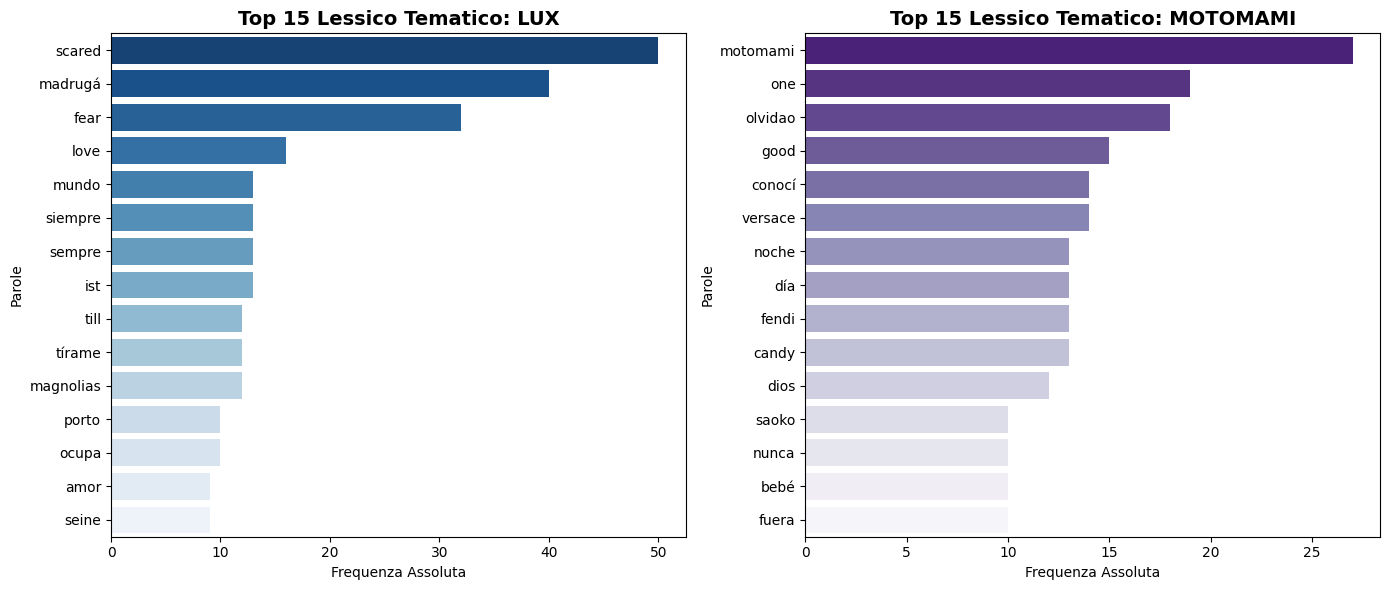

In [38]:
import pandas as pd
import os
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. CARICAMENTO DEL MASTER DEFINITIVO
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_master = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx')

if os.path.exists(percorso_master):
    df = pd.read_excel(percorso_master)
else:
    df = pd.read_csv('corpus canzoni(Foglio1).csv', sep=';', encoding='latin1')

# ==========================================
# 2. DEFINIZIONE DELLA STOP-LIST LESSICALE AVANZATA
# (Elimina ausiliari, verbi modali, pronomi e particelle vuote)
# ==========================================
stop_words_avanzate = {
    'ser', 'estar', 'haber', 'tener', 'poder', 'querer', 'deber', 'saber', 'ir', 'venir',
    'soy', 'eres', 'es', 'somos', 'sois', 'son', 'fui', 'fue', 'era', 'eras', 'éramos', 'será',
    'estoy', 'estás', 'está', 'estamos', 'están', 'estaba', 'estuve',
    'he', 'has', 'ha', 'hemos', 'habéis', 'han', 'había', 'hube',
    'tengo', 'tienes', 'tiene', 'tenemos', 'tenéis', 'tienen', 'tenía', 'tuve',
    'puedo', 'puedes', 'puede', 'podemos', 'podéis', 'pueden', 'podía', 'pude',
    'quiero', 'quieres', 'quiere', 'queremos', 'queréis', 'quieren', 'quería', 'quise',
    'sé', 'sabes', 'sabe', 'sabemos', 'sabéis', 'saben', 'sabía', 'supe',
    'voy', 'vas', 'va', 'vamos', 'vais', 'van', 'iba', 'fui',
    'hacer', 'hago', 'haces', 'hace', 'hacemos', 'hacen', 'hizo', 'hacía',
    'decir', 'digo', 'dices', 'dice', 'decimos', 'dicen', 'dijo', 'decía',
    'dar', 'doy', 'das', 'da', 'damos', 'dan', 'dio',
    # Articoli, pronomi, preposizioni, congiunzioni e particelle vuote
    'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'y', 'o', 'pero', 'si', 'no',
    'de', 'del', 'al', 'en', 'entre', 'hacia', 'hasta', 'para', 'por', 'sin', 'sobre', 'tras',
    'que', 'quien', 'donde', 'como', 'cuando', 'este', 'esta', 'estos', 'estas', 'ese', 'esa',
    'esos', 'esas', 'me', 'te', 'se', 'nos', 'os', 'le', 'les', 'lo', 'mi', 'tu', 'su',
    'yo', 'tú', 'ti', 'mí', 'mis', 'tus', 'sus', 'nuestro', 'vuestro',
    'the', 'and', 'to', 'of', 'in', 'is', 'it', 'you', 'that', 'he', 'was', 'for', 'on', 'are',
    'der', 'die', 'das', 'und', 'den', 'von', 'zu', 'dem', 'sich', 'des', 'auf', 'für',
    'il', 'lo', 'le', 'i', 'gli', 'uno', 'una', 'e', 'ma', 'per', 'con', 'su', 'da', 'di', 'tra', 'fra',
    'pa', 'mas', 'más', 'tan', 'bien', 'mal', 'asi', 'así', 'todo', 'toda', 'todos', 'todas',
    'algo', 'nada', 'aqui', 'aquí', 'alli', 'allí', 'ta', 'ra', 'so', 'na', 'pu', 'rá', 'tá', 'nonaino'
}

def estrai_sostantivi_aggettivi(testo):
    if not isinstance(testo, str):
        return []
    # Estraiamo parole alfabetiche ripulite
    parole = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑüÜàèìòùÀÈÌÒÙ]+\b', testo.lower())
    # Filtriamo escludendo le stop words e parole con meno di 3 lettere
    filtrate = [p for p in parole if p not in stop_words_avanzate and len(p) > 2]
    return filtrate

df['lessico_tematico'] = df['testo'].apply(estrai_sostantivi_aggettivi)

# ==========================================
# 3. SEPARAZIONE DEI DUE ALBUM (LUX vs MOTOMAMI)
# ==========================================
df_lux = df[df['album'].astype(str).str.contains('Lux', case=False, na=False)]
df_motomami = df[df['album'].astype(str).str.contains('Motomami', case=False, na=False)]

tokens_lux = []
for lista in df_lux['lessico_tematico']:
    tokens_lux.extend(lista)

tokens_motomami = []
for lista in df_motomami['lessico_tematico']:
    tokens_motomami.extend(lista)

freq_lux = Counter(tokens_lux)
freq_motomami = Counter(tokens_motomami)

df_freq_lux = pd.DataFrame(freq_lux.most_common(15), columns=['Parola', 'Frequenza'])
df_freq_mot = pd.DataFrame(freq_motomami.most_common(15), columns=['Parola', 'Frequenza'])

print("=== TOP 15 LESSICO TEMATICO: LUX ===")
display(df_freq_lux)

print("\n=== TOP 15 LESSICO TEMATICO: MOTOMAMI ===")
display(df_freq_mot)

# ==========================================
# 4. RAPPRESENTAZIONE GRAFICA COMPARATIVA
# ==========================================
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.barplot(data=df_freq_lux, x='Frequenza', y='Parola', palette='Blues_r', hue='Parola', legend=False)
plt.title('Top 15 Lessico Tematico: LUX', fontsize=14, fontweight='bold')
plt.xlabel('Frequenza Assoluta')
plt.ylabel('Parole')

plt.subplot(1, 2, 2)
sns.barplot(data=df_freq_mot, x='Frequenza', y='Parola', palette='Purples_r', hue='Parola', legend=False)
plt.title('Top 15 Lessico Tematico: MOTOMAMI', fontsize=14, fontweight='bold')
plt.xlabel('Frequenza Assoluta')
plt.ylabel('Parole')

plt.tight_layout()
plt.show()

Ho chiesto poi di estrarre la parola più frequente per ciascuna lingua o combinazione linguistica presente nel tuo corpus, mantenendo rigorosamente la logica di filtraggio per isolare sostantivi, aggettivi e termini tematici significativi (escludendo stop words, verbi ausiliari e particelle vuote)

In [39]:
import pandas as pd
import os
import re
from collections import Counter

# ==========================================
# 1. CARICAMENTO DEL MASTER DEFINITIVO
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_master = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx')

if os.path.exists(percorso_master):
    df = pd.read_excel(percorso_master)
else:
    df = pd.read_csv('corpus canzoni(Foglio1).csv', sep=';', encoding='latin1')

# Identifichiamo la colonna delle lingue (gestendo eventuali spazi nel nome)
col_lingua = next((c for c in df.columns if 'lingua' in c.lower()), 'lingue ')

# ==========================================
# 2. DEFINIZIONE DELLA STOP-LIST LESSICALE AVANZATA
# ==========================================
stop_words_avanzate = {
    'ser', 'estar', 'haber', 'tener', 'poder', 'querer', 'deber', 'saber', 'ir', 'venir',
    'soy', 'eres', 'es', 'somos', 'sois', 'son', 'fui', 'fue', 'era', 'eras', 'éramos', 'será',
    'estoy', 'estás', 'está', 'estamos', 'están', 'estaba', 'estuve',
    'he', 'has', 'ha', 'hemos', 'habéis', 'han', 'había', 'hube',
    'tengo', 'tienes', 'tiene', 'tenemos', 'tenéis', 'tienen', 'tenía', 'tuve',
    'puedo', 'puedes', 'puede', 'podemos', 'podéis', 'pueden', 'podía', 'pude',
    'quiero', 'quieres', 'quiere', 'queremos', 'queréis', 'quieren', 'quería', 'quise',
    'sé', 'sabes', 'sabe', 'sabemos', 'sabéis', 'saben', 'sabía', 'supe',
    'voy', 'vas', 'va', 'vamos', 'vais', 'van', 'iba', 'fui',
    'hacer', 'hago', 'haces', 'hace', 'hacemos', 'hacen', 'hizo', 'hacía',
    'decir', 'digo', 'dices', 'dice', 'decimos', 'dicen', 'dijo', 'decía',
    'dar', 'doy', 'das', 'da', 'damos', 'dan', 'dio',
    # Articoli, pronomi, preposizioni, congiunzioni e particelle vuote
    'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'y', 'o', 'pero', 'si', 'no',
    'de', 'del', 'al', 'en', 'entre', 'hacia', 'hasta', 'para', 'por', 'sin', 'sobre', 'tras',
    'que', 'quien', 'donde', 'como', 'cuando', 'este', 'esta', 'estos', 'estas', 'ese', 'esa',
    'esos', 'esas', 'me', 'te', 'se', 'nos', 'os', 'le', 'les', 'lo', 'mi', 'tu', 'su',
    'yo', 'tú', 'ti', 'mí', 'mis', 'tus', 'sus', 'nuestro', 'vuestro',
    'the', 'and', 'to', 'of', 'in', 'is', 'it', 'you', 'that', 'he', 'was', 'for', 'on', 'are',
    'der', 'die', 'das', 'und', 'den', 'von', 'zu', 'dem', 'sich', 'des', 'auf', 'für',
    'il', 'lo', 'le', 'i', 'gli', 'uno', 'una', 'e', 'ma', 'per', 'con', 'su', 'da', 'di', 'tra', 'fra',
    'pa', 'mas', 'más', 'tan', 'bien', 'mal', 'asi', 'así', 'todo', 'toda', 'todos', 'todas',
    'algo', 'nada', 'aqui', 'aquí', 'alli', 'allí', 'ta', 'ra', 'so', 'na', 'pu', 'rá', 'tá', 'nonaino'
}

# ==========================================
# 3. ESTRAZIONE E ANALISI PER CIASCUNA LINGUA
# ==========================================
report_lingue = []

for lingua in df[col_lingua].unique():
    df_lingua = df[df[col_lingua] == lingua]
    tokens_lingua = []

    for testo in df_lingua['testo']:
        if isinstance(testo, str):
            # Estrazione parole alfabetiche ripulite
            parole = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑüÜàèìòùÀÈÌÒÙ]+\b', testo.lower())
            # Filtriamo escludendo le stop words e parole con meno di 3 lettere
            filtrate = [p for p in parole if p not in stop_words_avanzate and len(p) > 2]
            tokens_lingua.extend(filtrate)

    # Contiamo le frequenze
    freq = Counter(tokens_lingua)
    if freq:
        piu_frequente, conteggio = freq.most_common(1)[0]
        report_lingue.append({
            'Lingua / Categoria': lingua,
            'Parola più frequente': piu_frequente,
            'Frequenza': conteggio
        })

# Creazione del DataFrame finale di riepilogo
df_report_lingue = pd.DataFrame(report_lingue)

print("=== PAROLA PIÙ FREQUENTE PER CIASCUNA LINGUA/CATEGORIA ===")
display(df_report_lingue)

# Salvataggio opzionale del report in Excel
percorso_report = os.path.join(cartella_progetto, '10. Report Parole per Lingua.xlsx')
df_report_lingue.to_excel(percorso_report, index=False)
print(f"\n📁 Report salvato in: {percorso_report}")

=== PAROLA PIÙ FREQUENTE PER CIASCUNA LINGUA/CATEGORIA ===


,Lingua / Categoria,Parola più frequente,Frequenza
0,Spagnolo,motomami,27
1,Inglese/ Spagnolo,outside,6
2,Spagnolo/ Giapponese/Inglese,scared,50
3,Italiano/Inglese,sempre,12
4,Inglese/Spagnolo/Tedesco,love,16
5,Spagnolo/Ucraino,madrugá,40
6,Spagnolo/Arabo/Inglese,ocupa,10
7,Spagnolo/Inglese,good,15
8,Portoghese/Spagnolo,ainda,7



📁 Report salvato in: /content/drive/MyDrive/Progetto-Rosalia/10. Report Parole per Lingua.xlsx


Chiedo poi un codice per  generare tre word clouds, una generale che riguarda le parole tematiche più frequenti di entrambi gli album, e due separate che rappresentino visivamente le parole piu comuni di lux  e quelle di motomami.

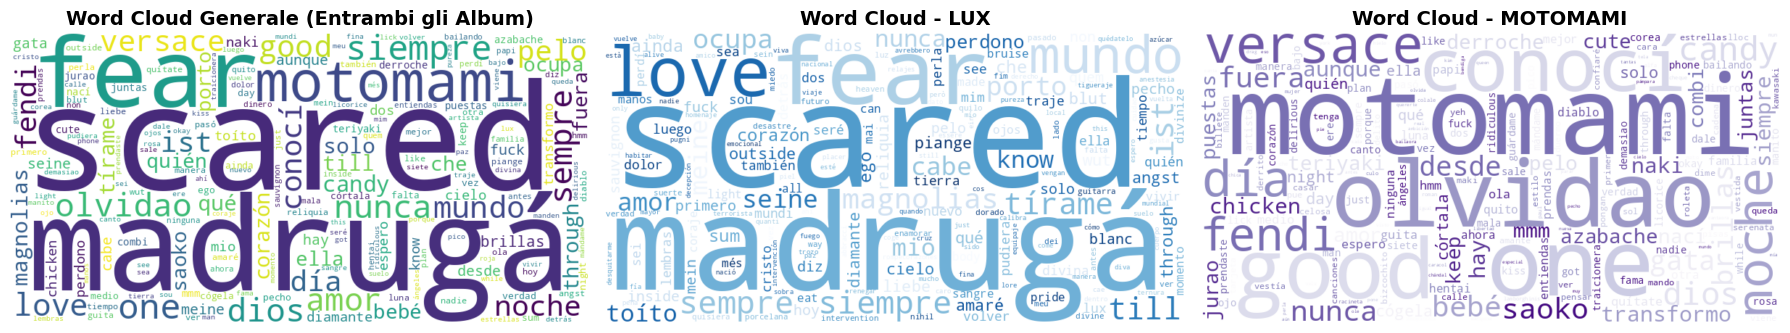

In [40]:
import pandas as pd
import os
import re
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# ==========================================
# 1. CARICAMENTO DATI E PULIZIA LESSICALE
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_master = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx')

if os.path.exists(percorso_master):
    df = pd.read_excel(percorso_master)
else:
    df = pd.read_csv('corpus canzoni(Foglio1).csv', sep=';', encoding='latin1')

stop_words_avanzate = {
    'ser', 'estar', 'haber', 'tener', 'poder', 'querer', 'deber', 'saber', 'ir', 'venir',
    'soy', 'eres', 'es', 'somos', 'sois', 'son', 'fui', 'fue', 'era', 'eras', 'éramos', 'será',
    'estoy', 'estás', 'está', 'estamos', 'están', 'estaba', 'estuve',
    'he', 'has', 'ha', 'hemos', 'habéis', 'han', 'había', 'hube',
    'tengo', 'tienes', 'tiene', 'tenemos', 'tenéis', 'tienen', 'tenía', 'tuve',
    'puedo', 'puedes', 'puede', 'podemos', 'podéis', 'pueden', 'podía', 'pude',
    'quiero', 'quieres', 'quiere', 'queremos', 'queréis', 'quieren', 'quería', 'quise',
    'sé', 'sabes', 'sabe', 'sabemos', 'sabéis', 'saben', 'sabía', 'supe',
    'voy', 'vas', 'va', 'vamos', 'vais', 'van', 'iba', 'fui',
    'hacer', 'hago', 'haces', 'hace', 'hacemos', 'hacen', 'hizo', 'hacía',
    'decir', 'digo', 'dices', 'dice', 'decimos', 'dicen', 'dijo', 'decía',
    'dar', 'doy', 'das', 'da', 'damos', 'dan', 'dio',
    'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'y', 'o', 'pero', 'si', 'no',
    'de', 'del', 'al', 'en', 'entre', 'hacia', 'hasta', 'para', 'por', 'sin', 'sobre', 'tras',
    'que', 'quien', 'donde', 'como', 'cuando', 'este', 'esta', 'estos', 'estas', 'ese', 'esa',
    'esos', 'esas', 'me', 'te', 'se', 'nos', 'os', 'le', 'les', 'lo', 'mi', 'tu', 'su',
    'yo', 'tú', 'ti', 'mí', 'mis', 'tus', 'sus', 'nuestro', 'vuestro',
    'the', 'and', 'to', 'of', 'in', 'is', 'it', 'you', 'that', 'he', 'was', 'for', 'on', 'are',
    'der', 'die', 'das', 'und', 'den', 'von', 'zu', 'dem', 'sich', 'des', 'auf', 'für',
    'il', 'lo', 'le', 'i', 'gli', 'uno', 'una', 'e', 'ma', 'per', 'con', 'su', 'da', 'di', 'tra', 'fra',
    'pa', 'mas', 'más', 'tan', 'bien', 'mal', 'asi', 'así', 'todo', 'toda', 'todos', 'todas',
    'algo', 'nada', 'aqui', 'aquí', 'alli', 'allí', 'ta', 'ra', 'so', 'na', 'pu', 'rá', 'tá', 'nonaino'
}

def estraici_tematici(testo):
    if not isinstance(testo, str):
        return []
    parole = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑüÜàèìòùÀÈÌÒÙ]+\b', testo.lower())
    filtrate = [p for p in parole if p not in stop_words_avanzate and len(p) > 2]
    return filtrate

df['lessico_tematico'] = df['testo'].apply(estraici_tematici)

# Separazione dei corpus per album
df_lux = df[df['album'].astype(str).str.contains('Lux', case=False, na=False)]
df_motomami = df[df['album'].astype(str).str.contains('Motomami', case=False, na=False)]

# Creazione delle liste di token aggregate
tokens_generali = []
for lista in df['lessico_tematico']: tokens_generali.extend(lista)

tokens_lux = []
for lista in df_lux['lessico_tematico']: tokens_lux.extend(lista)

tokens_motomami = []
for lista in df_motomami['lessico_tematico']: tokens_motomami.extend(lista)

# Convertiamo le frequenze in dizionari per le word clouds
freq_gen = dict(Counter(tokens_generali))
freq_l = dict(Counter(tokens_lux))
freq_m = dict(Counter(tokens_motomami))

# ==========================================
# 2. GENERAZIONE E PLOT DELLE WORD CLOUDS
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Word Cloud Generale
wc_gen = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate_from_frequencies(freq_gen)
axes[0].imshow(wc_gen, interpolation='bilinear')
axes[0].set_title('Word Cloud Generale (Entrambi gli Album)', fontsize=14, fontweight='bold')
axes[0].axis('off')

# 2. Word Cloud Lux
wc_lux = WordCloud(width=800, height=400, background_color='white', colormap='Blues').generate_from_frequencies(freq_l)
axes[1].imshow(wc_lux, interpolation='bilinear')
axes[1].set_title('Word Cloud - LUX', fontsize=14, fontweight='bold')
axes[1].axis('off')

# 3. Word Cloud Motomami
wc_moto = WordCloud(width=800, height=400, background_color='white', colormap='Purples').generate_from_frequencies(freq_m)
axes[2].imshow(wc_moto, interpolation='bilinear')
axes[2].set_title('Word Cloud - MOTOMAMI', fontsize=14, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()

le cloud words sono sature, richiedo un codice per crearle secondo le classifiche delle prime 15 piu frequenti create in precedenza per poi salvarle nella cartella drive e di Colab

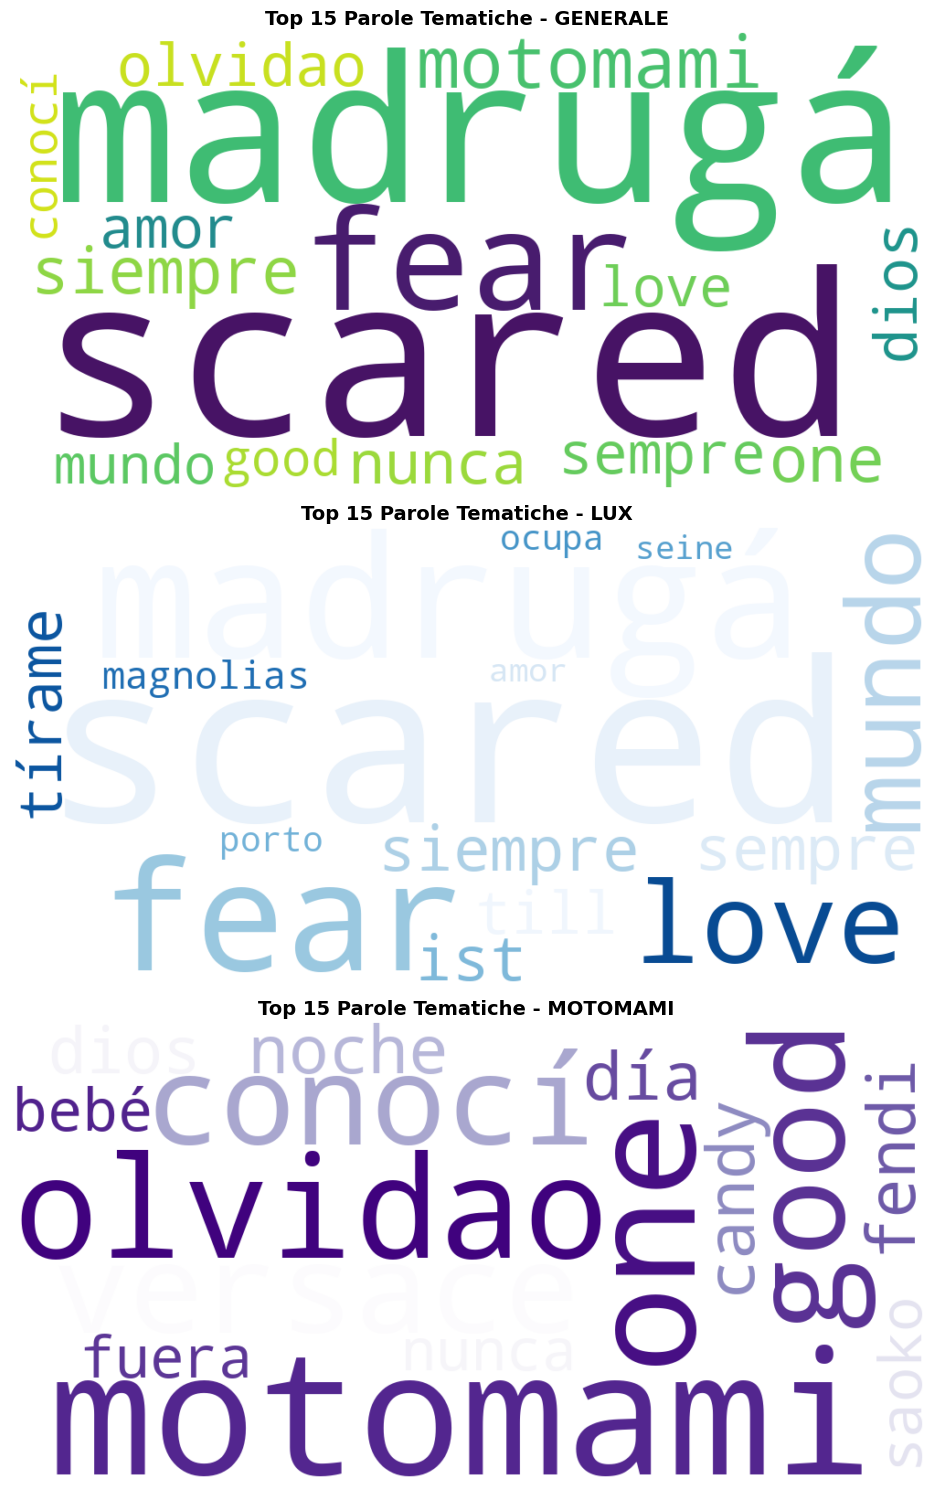

✨ Word clouds salvate con successo nella cartella Google Drive: /content/drive/MyDrive/Progetto-Rosalia


In [41]:
import pandas as pd
import os
import re
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# ==========================================
# 1. CARICAMENTO DATI E PULIZIA LESSICALE
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
os.makedirs(cartella_progetto, exist_ok=True)

percorso_master = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx')
if os.path.exists(percorso_master):
    df = pd.read_excel(percorso_master)
else:
    df = pd.read_csv('corpus canzoni(Foglio1).csv', sep=';', encoding='latin1')

stop_words_avanzate = {
    'ser', 'estar', 'haber', 'tener', 'poder', 'querer', 'deber', 'saber', 'ir', 'venir',
    'soy', 'eres', 'es', 'somos', 'sois', 'son', 'fui', 'fue', 'era', 'eras', 'éramos', 'será',
    'estoy', 'estás', 'está', 'estamos', 'están', 'estaba', 'estuve',
    'he', 'has', 'ha', 'hemos', 'habéis', 'han', 'había', 'hube',
    'tengo', 'tienes', 'tiene', 'tenemos', 'tenéis', 'tienen', 'tenía', 'tuve',
    'puedo', 'puedes', 'puede', 'podemos', 'podéis', 'pueden', 'podía', 'pude',
    'quiero', 'quieres', 'quiere', 'queremos', 'queréis', 'quieren', 'quería', 'quise',
    'sé', 'sabes', 'sabe', 'sabemos', 'sabéis', 'saben', 'sabía', 'supe',
    'voy', 'vas', 'va', 'vamos', 'vais', 'van', 'iba', 'fui',
    'hacer', 'hago', 'haces', 'hace', 'hacemos', 'hacen', 'hizo', 'hacía',
    'decir', 'digo', 'dices', 'dice', 'decimos', 'dicen', 'dijo', 'decía',
    'dar', 'doy', 'das', 'da', 'damos', 'dan', 'dio',
    'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'y', 'o', 'pero', 'si', 'no',
    'de', 'del', 'al', 'en', 'entre', 'hacia', 'hasta', 'para', 'por', 'sin', 'sobre', 'tras',
    'que', 'quien', 'donde', 'como', 'cuando', 'este', 'esta', 'estos', 'estas', 'ese', 'esa',
    'esos', 'esas', 'me', 'te', 'se', 'nos', 'os', 'le', 'les', 'lo', 'mi', 'tu', 'su',
    'yo', 'tú', 'ti', 'mí', 'mis', 'tus', 'sus', 'nuestro', 'vuestro',
    'the', 'and', 'to', 'of', 'in', 'is', 'it', 'you', 'that', 'he', 'was', 'for', 'on', 'are',
    'der', 'die', 'das', 'und', 'den', 'von', 'zu', 'dem', 'sich', 'des', 'auf', 'für',
    'il', 'lo', 'le', 'i', 'gli', 'uno', 'una', 'e', 'ma', 'per', 'con', 'su', 'da', 'di', 'tra', 'fra',
    'pa', 'mas', 'más', 'tan', 'bien', 'mal', 'asi', 'así', 'todo', 'toda', 'todos', 'todas',
    'algo', 'nada', 'aqui', 'aquí', 'alli', 'allí', 'ta', 'ra', 'so', 'na', 'pu', 'rá', 'tá', 'nonaino'
}

def estraici_tematici(testo):
    if not isinstance(testo, str):
        return []
    parole = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑüÜàèìòùÀÈÌÒÙ]+\b', testo.lower())
    filtrate = [p for p in parole if p not in stop_words_avanzate and len(p) > 2]
    return filtrate

df['lessico_tematico'] = df['testo'].apply(estraici_tematici)

df_lux = df[df['album'].astype(str).str.contains('Lux', case=False, na=False)]
df_motomami = df[df['album'].astype(str).str.contains('Motomami', case=False, na=False)]

tokens_gen, tokens_lux, tokens_moto = [], [], []
for l in df['lessico_tematico']: tokens_gen.extend(l)
for l in df_lux['lessico_tematico']: tokens_lux.extend(l)
for l in df_motomami['lessico_tematico']: tokens_moto.extend(l)

# ==========================================
# 2. SELEZIONE RIGOROSA DELLE TOP 15
# ==========================================
freq_gen_15 = dict(Counter(tokens_gen).most_common(15))
freq_lux_15 = dict(Counter(tokens_lux).most_common(15))
freq_moto_15 = dict(Counter(tokens_moto).most_common(15))

# ==========================================
# 3. GENERAZIONE E SALVATAGGIO DELLE WORD CLOUDS
# ==========================================
config_wc = dict(width=1000, height=500, background_color='white', max_words=15, relative_scaling=0.5)

# 1. Generale
wc_gen = WordCloud(**config_wc, colormap='viridis').generate_from_frequencies(freq_gen_15)
path_gen = os.path.join(cartella_progetto, 'WordCloud_Generale_Top15.png')
wc_gen.to_file(path_gen)

# 2. Lux
wc_lux = WordCloud(**config_wc, colormap='Blues').generate_from_frequencies(freq_lux_15)
path_lux = os.path.join(cartella_progetto, 'WordCloud_Lux_Top15.png')
wc_lux.to_file(path_lux)

# 3. Motomami
wc_moto = WordCloud(**config_wc, colormap='Purples').generate_from_frequencies(freq_moto_15)
path_moto = os.path.join(cartella_progetto, 'WordCloud_Motomami_Top15.png')
wc_moto.to_file(path_moto)

# Visualizzazione inline in Colab
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

axes[0].imshow(wc_gen, interpolation='bilinear')
axes[0].set_title('Top 15 Parole Tematiche - GENERALE', fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(wc_lux, interpolation='bilinear')
axes[1].set_title('Top 15 Parole Tematiche - LUX', fontsize=14, fontweight='bold')
axes[1].axis('off')

axes[2].imshow(wc_moto, interpolation='bilinear')
axes[2].set_title('Top 15 Parole Tematiche - MOTOMAMI', fontsize=14, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()

print(f"✨ Word clouds salvate con successo nella cartella Google Drive: {cartella_progetto}")

isolare prima il calcolo dei types (le parole uniche, ovvero il vocabolario effettivo di ciascun brano) è un passaggio fondamentale e molto più pulito da analizzare prima di passare ai rapporti statistici come il TTR.

Facciamo questo passo in modo dedicato, creando un file specifico che estrae e salva l'elenco delle parole uniche per ogni canzone.

In [44]:
import pandas as pd
import ast

# ==========================================
# 1. CONFIGURAZIONE DEI PERCORSI
# ==========================================
percorso_partenza = 'Progetto-Rosalia/6. Corpus Rosalia Tokenizzato.xlsx'
percorso_output = 'Progetto-Rosalia/7. Corpus Rosalia Types.xlsx'

# ==========================================
# 2. CARICAMENTO DEL DATASET TOKENIZZATO
# ==========================================
print("Caricamento del corpus tokenizzato in corso...")
df = pd.read_excel(percorso_partenza)

# Riconvertiamo la colonna in lista se necessario
def converte_in_lista(valore):
    if isinstance(valore, list):
        return valore
    try:
        return ast.literal_eval(valore)
    except:
        return str(valore).split()

df['lista_token'] = df['lista_token'].apply(converte_in_lista)

# ==========================================
# 3. ESTRAZIONE DEI TYPES (Parole Uniche)
# ==========================================
def estrai_types(tokens):
    if not tokens:
        return []
    # Usiamo 'set' per eliminare i duplicati e 'sorted' per ordinare alfabeticamente il vocabolario del brano
    return sorted(list(set(tokens)))

# Creiamo le colonne dedicate ai types e al loro conteggio
df['lista_types'] = df['lista_token'].apply(estrai_types)
df['num_types'] = df['lista_types'].apply(len)

# ==========================================
# 4. SALVATAGGIO DEL NUOVO STADIO
# ==========================================
df.to_excel(percorso_output, index=False)

print(f"Output generato: 7. Corpus Rosalia Types.xlsx")
print(f"Canzoni elaborate: {len(df)}")

# Mostriamo un'anteprima dei types per i primi brani
display(df[['num_parole_totali', 'num_types', 'lista_types']].head(3))

Caricamento del corpus tokenizzato in corso...
Output generato: 7. Corpus Rosalia Types.xlsx
Canzoni elaborate: 30


,num_parole_totali,num_types,lista_types
0,104,42,"[a, amaré, balanza, beso, cielo, de, deportes,..."
1,232,119,"[a, ahí, aires, amiga, amor, aprendí, aquí, ar..."
2,232,116,"[a, absència, alive, all, amor, body, bruise, ..."


Il passo successivo naturale nella nostra pipeline di Digital Humanities è il calcolo della ricchezza lessicale, utilizzando una delle metriche standard più importanti: il Type-Token Ratio (TTR).

Il TTR si calcola dividendo il numero di parole uniche (types) per il numero totale di parole (tokens): più alto è il valore, più vario e ricco è il vocabolario usato nel brano.

In [43]:
import pandas as pd
import ast

# ==========================================
# 1. CONFIGURAZIONE DEI PERCORSI
# ==========================================
percorso_partenza = 'Progetto-Rosalia/6. Corpus Rosalia Tokenizzato.xlsx'
percorso_output = 'Progetto-Rosalia/7. Corpus Rosalia Ricchezza Lessicale.xlsx'

# ==========================================
# 2. CARICAMENTO DEL DATASET
# ==========================================
print("Caricamento del file 'Tokenizzato' in corso...")
df = pd.read_excel(percorso_partenza)

# Assicuriamoci che la colonna dei token venga letta correttamente come lista
# (A volte salvando in Excel le liste diventano stringhe, quindi le riconvertiamo se necessario)
def converte_in_lista(valore):
    if isinstance(valore, list):
        return valore
    try:
        return ast.literal_eval(valore)
    except:
        return str(valore).split()

df['lista_token'] = df['lista_token'].apply(converte_in_lista)

# ==========================================
# 3. CALCOLO DELLA RICCHEZZA LESSICALE (TTR)
# ==========================================
def calcola_ttr(tokens):
    if not tokens or len(tokens) == 0:
        return 0, 0, 0.0

    num_tokens = len(tokens)                  # Parole totali
    types_unici = set(tokens)
    num_types = len(types_unici)              # Parole uniche (vocabolario)
    ttr = num_types / num_tokens              # Type-Token Ratio

    return num_types, num_tokens, round(ttr, 4)

# Applichiamo la funzione ricavando le nuove metriche
risultati = df['lista_token'].apply(calcola_ttr)
df['num_parole_uniche'] = [r[0] for r in risultati]
df['num_parole_totali'] = [r[1] for r in risultati]
df['ttr'] = [r[2] for r in risultati]

# ==========================================
# 4. SALVATAGGIO DEL NUOVO STADIO
# ==========================================
df.to_excel(percorso_output, index=False)

print(f"Output generato: 7. Corpus Rosalia Ricchezza Lessicale.xlsx")
print(f"TTR medio dell'intero corpus: {df['ttr'].mean():.4f}")

# Mostriamo un'anteprima dei risultati
display(df[['num_parole_totali', 'num_parole_uniche', 'ttr']].head(5))

Caricamento del file 'Tokenizzato' in corso...
Output generato: 7. Corpus Rosalia Ricchezza Lessicale.xlsx
TTR medio dell'intero corpus: 0.4469


,num_parole_totali,num_parole_uniche,ttr
0,104,42,0.4038
1,232,119,0.5129
2,232,116,0.5000
3,308,100,0.3247
4,214,119,0.5561


 Più il valore si avvicina a 1.0, più il testo ha un vocabolario vario e ricco con poche ripetizioni. Valori più bassi indicano una scrittura più ripetitiva (molto comune nei brani musicali a causa dei ritornelli). Ad esempio, il quarto brano ha un TTR di $0.32$, mentre il quinto arriva a $0.55$, indicando una maggiore varietà lessicale.   

In [45]:
import pandas as pd

# Carichiamo il file con la ricchezza lessicale
percorso = 'Progetto-Rosalia/7. Corpus Rosalia Ricchezza Lessicale.xlsx'
df = pd.read_excel(percorso)

# Troviamo gli indici del TTR massimo e minimo
idx_max = df['ttr'].idxmax()
idx_min = df['ttr'].idxmin()

# Verifichiamo se esiste una colonna del titolo
col_titolo = next((col for col in ['titolo', 'title', 'brano', 'name'] if col in df.columns), None)
nome_max = df.loc[idx_max, col_titolo] if col_titolo else f"Brano alla riga {idx_max + 1}"
nome_min = df.loc[idx_min, col_titolo] if col_titolo else f"Brano alla riga {idx_min + 1}"

print("--- CLASSIFICA RICCHEZZA LESSICALE (TTR) ---")
print(f"\n📈 TTR PIÙ ALTO (Maggiore varietà lessicale):")
print(f"   - Brano/ID: {nome_max}")
print(f"   - Valore TTR: {df.loc[idx_max, 'ttr']}")
print(f"   - Parole totali: {df.loc[idx_max, 'num_parole_totali']} | Parole uniche: {df.loc[idx_max, 'num_parole_uniche']}")

print(f"\n📉 TTR PIÙ BASSO (Maggiore ripetitività/ritornelli):")
print(f"   - Brano/ID: {nome_min}")
print(f"   - Valore TTR: {df.loc[idx_min, 'ttr']}")
print(f"   - Parole totali: {df.loc[idx_min, 'num_parole_totali']} | Parole uniche: {df.loc[idx_min, 'num_parole_uniche']}")

--- CLASSIFICA RICCHEZZA LESSICALE (TTR) ---

📈 TTR PIÙ ALTO (Maggiore varietà lessicale):
   - Brano/ID: Abcdefg
   - Valore TTR: 0.6372
   - Parole totali: 113 | Parole uniche: 72

📉 TTR PIÙ BASSO (Maggiore ripetitività/ritornelli):
   - Brano/ID: Candy
   - Valore TTR: 0.2353
   - Parole totali: 289 | Parole uniche: 68


A questo punto, chiedo al LLM di mostrarmi la lista dei venti token più ricorrenti di tutto il corpus.

In [46]:
import pandas as pd
import ast
from collections import Counter

# ==========================================
# 1. CONFIGURAZIONE DEI PERCORSI
# ==========================================
percorso_partenza = 'Progetto-Rosalia/6. Corpus Rosalia Tokenizzato.xlsx'

# ==========================================
# 2. CARICAMENTO DEL DATASET TOKENIZZATO
# ==========================================
print("Caricamento del corpus in corso...")
df = pd.read_excel(percorso_partenza)

# Riconvertiamo la colonna dei token in lista se necessario
def converte_in_lista(valore):
    if isinstance(valore, list):
        return valore
    try:
        return ast.literal_eval(valore)
    except:
        return str(valore).split()

df['lista_token'] = df['lista_token'].apply(converte_in_lista)

# ==========================================
# 3. UNIONE DEI TOKEN E CONTEGGIO GLOBALE
# ==========================================
tutti_i_token = []
for lista in df['lista_token']:
    tutti_i_token.extend(lista)

# Usiamo Counter per contare la frequenza di ciascuna parola nel corpus totale
conteggio_frequenze = Counter(tutti_i_token)

# Estraiamo i 20 token più comuni
top_20 = conteggio_frequenze.most_common(20)

# Creiamo un DataFrame per visualizzare i risultati in modo ordinato e pulito
df_top20 = pd.DataFrame(top_20, columns=['Token', 'Frequenza'])

print("\n--- CLASSIFICA: I 20 TOKEN PIÙ RICORRENTI NEL CORPUS ---")
display(df_top20)

# Opzionale: salviamo la classifica in un file Excel dedicato
percorso_output = 'Progetto-Rosalia/8. Corpus Rosalia Top 20 Frequenze.xlsx'
df_top20.to_excel(percorso_output, index=False)
print(f"\nFile della classifica salvato in: {percorso_output}")

Caricamento del corpus in corso...

--- CLASSIFICA: I 20 TOKEN PIÙ RICORRENTI NEL CORPUS ---


,Token,Frequenza
0,que,235
1,de,226
2,la,184
3,me,167
4,y,145
5,el,136
6,no,135
7,en,132
8,a,111
9,yo,103



File della classifica salvato in: Progetto-Rosalia/8. Corpus Rosalia Top 20 Frequenze.xlsx


eliminare le cosiddette stop words (parole vuote come articoli, preposizioni, congiunzioni, pronomi e ausiliari) permette di ripulire la statistica e far emergere finalmente il lessico pieno, cioè i sostantivi, i verbi significativi e gli aggettivi che caratterizzano davvero lo stile e i temi dei testi di Rosalía.

filtra il corpus rimuovendo le parole grammaticali vuote, salva un nuovo file Excel dedicato e genera la classifica aggiornata dei 20 token più ricorrenti.

In [47]:
import pandas as pd
import ast
from collections import Counter

# ==========================================
# 1. CONFIGURAZIONE DEI PERCORSI
# ==========================================
percorso_partenza = 'Progetto-Rosalia/6. Corpus Rosalia Tokenizzato.xlsx'
percorso_output = 'Progetto-Rosalia/8. Corpus Rosalia Senza Stopwords.xlsx'

# ==========================================
# 2. CARICAMENTO DEL DATASET
# ==========================================
print("Caricamento del corpus tokenizzato in corso...")
df = pd.read_excel(percorso_partenza)

def converte_in_lista(valore):
    if isinstance(valore, list):
        return valore
    try:
        return ast.literal_eval(valore)
    except:
        return str(valore).split()

df['lista_token'] = df['lista_token'].apply(converte_in_lista)

# ==========================================
# 3. DEFINIZIONE DELLE STOP WORDS (Spagnolo)
# ==========================================
# Includiamo articoli, pronomi, preposizioni, congiunzioni e ausiliari/verbi ad alta frequenza
stop_words_spagnolo = {
    'que', 'de', 'la', 'el', 'en', 'y', 'a', 'los', 'las', 'un', 'una', 'unos', 'unas',
    'por', 'con', 'para', 'su', 'sus', 'como', 'pero', 'mas', 'más', 'o', 'u', 'e',
    'lo', 'le', 'les', 'me', 'te', 'se', 'nos', 'os', 'yo', 'tu', 'tú', 'él', 'ella',
    'nosotros', 'vosotros', 'ellos', 'ellas', 'mi', 'mis', 'tu', 'tus', 'su', 'sus',
    'esta', 'este', 'estos', 'estas', 'ese', 'eso', 'esa', 'esos', 'esas', 'aquel',
    'aquella', 'aquellos', 'aquellas', 'ni', 'sin', 'sobre', 'entre', 'hasta', 'desde',
    'durante', 'mediante', 'contra', 'hacia', 'tras', 'según', 'bajo', 'al', 'del',
    'es', 'son', 'fue', 'fueron', 'ser', 'estar', 'haber', 'tiene', 'tienen', 'hay'
}

# ==========================================
# 4. RIMOZIONE E RICALCOLO DELLE FREQUENZE
# ==========================================
def rimuovi_stopwords(tokens):
    if not tokens:
        return []
    # Filtriamo tenendo solo le parole che non sono presenti nelle stop words
    return [str(t).lower() for t in tokens if str(t).lower() not in stop_words_spagnolo]

# Creiamo la nuova colonna pulita nel DataFrame
df['token_senza_stopwords'] = df['lista_token'].apply(rimuovi_stopwords)

# Uniamo tutti i token filtrati per ottenere la nuova classifica globale
tutti_i_token_filtrati = []
for lista in df['token_senza_stopwords']:
    tutti_i_token_filtrati.extend(lista)

conteggio_filtrato = Counter(tutti_i_token_filtrati)
top_20_filtrati = conteggio_filtrato.most_common(20)

# Creazione del DataFrame per la visualizzazione
df_top20_filtrati = pd.DataFrame(top_20_filtrati, columns=['Token (Significativo)', 'Frequenza'])

# ==========================================
# 5. SALVATAGGIO DEL NUOVO STADIO
# ==========================================
df.to_excel(percorso_output, index=False)

print(f"\nProcesso completato con successo!")
print(f"File salvato in: {percorso_output}")
print("\n--- CLASSIFICA AGGIORNATA: I 20 TOKEN PIÙ RICORRENTI (Senza Stop Words) ---")
display(df_top20_filtrati)

Caricamento del corpus tokenizzato in corso...

Processo completato con successo!
File salvato in: Progetto-Rosalia/8. Corpus Rosalia Senza Stopwords.xlsx

--- CLASSIFICA AGGIORNATA: I 20 TOKEN PIÙ RICORRENTI (Senza Stop Words) ---


,Token (Significativo),Frequenza
0,no,135
1,si,50
2,scared,50
3,so,41
4,madrugá,40
5,ya,36
6,ti,35
7,you,32
8,fear,32
9,nonaino,32


nella classifica compaiono ancora parole come "no", "si", "ya", "ti", "pa", "mi" o "i" che si comportano come stop words o forme contratte/avverbi frequenti che sporcano l'analisi del lessico pieno.

Questo succede perché il set standard di stop words che abbiamo usato è generico per lo spagnolo letterario, ma nei testi di Rosalía (che mescolano slang, termini gergali, abbreviazioni come pa invece di para, intercalari come nonaino o parole in inglese come scared e fear) abbiamo bisogno di una pulizia ancora più sartoriale e mirata. Aggiorniamo la lista inserendo esplicitamente tutte queste parole di servizio e intercalari ricorrenti (no, si, ya, ti, pa, mi, i, ecc.) in modo da pulire definitivamente la classifica.

In [48]:
import pandas as pd
import ast
from collections import Counter

# ==========================================
# 1. CARICAMENTO E AGGIORNAMENTO STOP WORDS
# ==========================================
percorso_partenza = 'Progetto-Rosalia/6. Corpus Rosalia Tokenizzato.xlsx'
percorso_output = 'Progetto-Rosalia/8. Corpus Rosalia Senza Stopwords.xlsx'

df = pd.read_excel(percorso_partenza)

def converte_in_lista(valore):
    if isinstance(valore, list):
        return valore
    try:
        return ast.literal_eval(valore)
    except:
        return str(valore).split()

df['lista_token'] = df['lista_token'].apply(converte_in_lista)

# Stop words estese e personalizzate per includere slang, avverbi frequenti e intercalari di Rosalía
stop_words_personalizzate = {
    # Articoli, pronomi, preposizioni, congiunzioni base
    'que', 'de', 'la', 'el', 'en', 'y', 'a', 'los', 'las', 'un', 'una', 'unos', 'unas',
    'por', 'con', 'para', 'su', 'sus', 'como', 'pero', 'mas', 'más', 'o', 'u', 'e',
    'lo', 'le', 'les', 'me', 'te', 'se', 'nos', 'os', 'yo', 'tu', 'tú', 'él', 'ella',
    'nosotros', 'vosotros', 'ellos', 'ellas', 'mi', 'mis', 'tu', 'tus', 'su', 'sus',
    'esta', 'este', 'estos', 'estas', 'ese', 'eso', 'esa', 'esos', 'esas', 'aquel',
    'aquella', 'aquellos', 'aquellas', 'ni', 'sin', 'sobre', 'entre', 'hasta', 'desde',
    'durante', 'mediante', 'contra', 'hacia', 'tras', 'según', 'bajo', 'al', 'del',
    'es', 'son', 'fue', 'fueron', 'ser', 'estar', 'haber', 'tiene', 'tienen', 'hay',

    # Avverbi, intercalari e forme gergali da escludere emersi dall'analisi
    'no', 'sí', 'si', 'ya', 'ti', 'pa', 'mi', 'mí', 'i', 'and', 'the', 'to', 'a',
    'ya', 'que', 'oh', 'ah', 'ey', 'e', 'ay', 'na', 'pa', 'pal'
}

# ==========================================
# 2. FILTRAGGIO E RICALCOLO
# ==========================================
def rimuovi_stopwords_custom(tokens):
    if not tokens:
        return []
    return [str(t).lower() for t in tokens if str(t).lower() not in stop_words_personalizzate]

df['token_senza_stopwords'] = df['lista_token'].apply(rimuovi_stopwords_custom)

tutti_i_token_filtrati = []
for lista in df['token_senza_stopwords']:
    tutti_i_token_filtrati.extend(lista)

conteggio_filtrato = Counter(tutti_i_token_filtrati)
top_20_filtrati = conteggio_filtrato.most_common(20)

df_top20_filtrati = pd.DataFrame(top_20_filtrati, columns=['Token (Lessico Pieno)', 'Frequenza'])

# ==========================================
# 3. SALVATAGGIO
# ==========================================
df.to_excel(percorso_output, index=False)

print("--- CLASSIFICA AGGIORNATA E PULITA (Lessico Pieno) ---")
display(df_top20_filtrati)

--- CLASSIFICA AGGIORNATA E PULITA (Lessico Pieno) ---


,Token (Lessico Pieno),Frequenza
0,scared,50
1,so,41
2,madrugá,40
3,you,32
4,fear,32
5,nonaino,32
6,motomami,27
7,quiero,25
8,soy,22
9,has,22


estendere le regole di filtraggio a tutte le lingue presenti nel corpus (aggiungendo quindi le stop words inglesi come you, the, to, and, ecc.) ti permette di avere una classifica pulita e omogenea, indipendentemente dal fatto che Rosalía inserisca termini o versi bilingui nei suoi brani.

In [49]:
import pandas as pd
import ast
from collections import Counter

# ==========================================
# 1. CARICAMENTO E CONFIGURAZIONE PERCORSI
# ==========================================
percorso_partenza = 'Progetto-Rosalia/6. Corpus Rosalia Tokenizzato.xlsx'
percorso_output = 'Progetto-Rosalia/8. Corpus Rosalia Senza Stopwords Universale_Totale.xlsx'

df = pd.read_excel(percorso_partenza)

def converte_in_lista(valore):
    if isinstance(valore, list):
        return valore
    try:
        return ast.literal_eval(valore)
    except:
        return str(valore).split()

df['lista_token'] = df['lista_token'].apply(converte_in_lista)

# ==========================================
# 2. STOP WORDS UNIVERSALI (6 Lingue + Slang)
# ==========================================
stop_words_universali_totali = {
    # --- Spagnolo ---
    'que', 'de', 'la', 'el', 'en', 'y', 'a', 'los', 'las', 'un', 'una', 'unos', 'unas',
    'por', 'con', 'para', 'su', 'sus', 'como', 'pero', 'mas', 'más', 'o', 'u', 'e',
    'lo', 'le', 'les', 'me', 'te', 'se', 'nos', 'os', 'yo', 'tu', 'tú', 'él', 'ella',
    'nosotros', 'vosotros', 'ellos', 'ellas', 'mi', 'mis', 'tu', 'tus', 'su', 'sus',
    'esta', 'este', 'estos', 'estas', 'ese', 'eso', 'esa', 'esos', 'esas', 'aquel',
    'aquella', 'aquellos', 'aquellas', 'ni', 'sin', 'sobre', 'entre', 'hasta', 'desde',
    'durante', 'mediante', 'contra', 'hacia', 'tras', 'según', 'bajo', 'al', 'del',
    'es', 'son', 'fue', 'fueron', 'ser', 'estar', 'haber', 'tiene', 'tienen', 'hay',

    # --- Inglese ---
    'you', 'the', 'to', 'a', 'and', 'i', 'it', 'is', 'in', 'of', 'for', 'on', 'with',
    'he', 'she', 'they', 'we', 'my', 'your', 'his', 'her', 'their', 'this', 'that',
    'be', 'are', 'was', 'were', 'have', 'has', 'do', 'does', 'not', 'or', 'an', 'at',
    'from', 'by', 'but', 'all', 'so', 'if', 'out', 'up', 'about', 'get', 'got', 'me',

    # --- Catalano / Portoghese ---
    'el', 'la', 'els', 'les', 'un', 'una', 'uns', 'unes', 'i', 'o', 'per', 'amb',
    'de', 'del', 'dels', 'en', 'a', 'al', 'als', 'que', 'com', 'no', 'sí',
    'um', 'uma', 'e', 'do', 'da', 'dos', 'das', 'em', 'no', 'na', 'nos', 'nas',

    # --- Italiano (Articoli, pronomi, preposizioni, congiunzioni) ---
    'il', 'lo', 'la', 'i', 'gli', 'le', 'un', 'uno', 'una', 'e', 'anche', 'o', 'ma',
    'se', 'per', 'di', 'a', 'da', 'in', 'con', 'su', 'per', 'tra', 'fra', 'che',
    'chi', 'cui', 'non', 'più', 'come', 'sono', 'è', 'ho', 'ha', 'questo', 'quello',
    'io', 'tu', 'lui', 'lei', 'noi', 'voi', 'loro', 'mi', 'ti', 'si', 'ci', 'vi',

    # --- Tedesco (Articoli, pronomi, preposizioni, congiunzioni) ---
    'der', 'die', 'das', 'den', 'dem', 'des', 'ein', 'eine', 'eines', 'einer', 'einem',
    'und', 'in', 'zu', 'den', 'von', 'mit', 'auf', 'für', 'an', 'ist', 'im', 'am',
    'sich', 'auch', 'als', 'an', 'nach', 'wie', 'es', 'er', 'sie', 'wir', 'ihr',
    'ich', 'du', 'mein', 'dein', 'sein', 'ihr', 'nicht', 'aber', 'oder', 'wenn',

    # --- Slang, Intercalari e Onomatopee ricorrenti ---
    'no', 'sí', 'si', 'ya', 'ti', 'pa', 'mi', 'mí', 'oh', 'ah', 'ey', 'ay', 'na', 'pal', 'nonaino',
    'e', 'eh', 'woah', 'yeah', 'ta', 'to'
}

# ==========================================
# 3. FILTRAGGIO E RICALCOLO GLOBALE
# ==========================================
def rimuovi_stopwords_totali(tokens):
    if not tokens:
        return []
    return [str(t).lower() for t in tokens if str(t).lower() not in stop_words_universali_totali]

df['token_senza_stopwords'] = df['lista_token'].apply(rimuovi_stopwords_totali)

tutti_i_token_filtrati = []
for lista in df['token_senza_stopwords']:
    tutti_i_token_filtrati.extend(lista)

conteggio_filtrato = Counter(tutti_i_token_filtrati)
top_20_filtrati = conteggio_filtrato.most_common(20)

df_top20_filtrati = pd.DataFrame(top_20_filtrati, columns=['Token (Lessico Pieno 6 Lingue)', 'Frequenza'])

# ==========================================
# 4. SALVATAGGIO DEL NUOVO STADIO
# ==========================================
df.to_excel(percorso_output, index=False)

print("--- CLASSIFICA AGGIORNATA (Filtro Universale a 6 Lingue) ---")
display(df_top20_filtrati)
print(f"\nFile salvato con successo in: {percorso_output}")

--- CLASSIFICA AGGIORNATA (Filtro Universale a 6 Lingue) ---


,Token (Lessico Pieno 6 Lingue),Frequenza
0,scared,50
1,madrugá,40
2,fear,32
3,motomami,27
4,quiero,25
5,soy,22
6,siempre,21
7,tarará,20
8,cuando,19
9,dios,18



File salvato con successo in: Progetto-Rosalia/8. Corpus Rosalia Senza Stopwords Universale_Totale.xlsx


n quanti e quali brani compare la parola "scared", estraendone anche il titolo (o l'indice della traccia) e il conteggio delle occorrenze per ciascun brano.

In [50]:
import pandas as pd
import ast

# ==========================================
# 1. CARICAMENTO DEL CORPUS TOKENIZZATO
# ==========================================
# Utilizziamo il file con i token (o quello pulito)
percorso_partenza = 'Progetto-Rosalia/6. Corpus Rosalia Tokenizzato.xlsx'
df = pd.read_excel(percorso_partenza)

def converte_in_lista(valore):
    if isinstance(valore, list):
        return valore
    try:
        return ast.literal_eval(valore)
    except:
        return str(valore).split()

df['lista_token'] = df['lista_token'].apply(converte_in_lista)

# Cerchiamo la parola chiave (in minuscolo per sicurezza)
parola_chiave = 'scared'

# Verifichiamo se esiste una colonna per il titolo del brano
col_titolo = next((col for col in ['titolo', 'title', 'brano', 'name'] if col in df.columns), None)

# ==========================================
# 2. RICERCA E CONTEGGIO
# ==========================================
risultati_ricerca = []

for indice, riga in df.iterrows():
    tokens = [str(t).lower() for t in riga['lista_token']]
    conteggio = tokens.count(parola_chiave)

    if conteggio > 0:
        nome_brano = riga[col_titolo] if col_titolo else f"Brano #{indice + 1}"
        risultati_ricerca.append({
            'Indice Riga': indice + 1,
            'Brano': nome_brano,
            'Occorrenze': conteggio
        })

# Creiamo un DataFrame con i risultati
df_risultati = pd.DataFrame(risultati_ricerca)

print(f"=== RISULTATI DELLA RICERCA PER LA PAROLA: '{parola_chiave}' ===")
print(f"La parola compare in un totale di {len(df_risultati)} brano/i.\n")

if not df_risultati.empty:
    display(df_risultati)
else:
    print("La parola cercata non è stata trovata in nessun brano del corpus.")

=== RISULTATI DELLA RICERCA PER LA PAROLA: 'scared' ===
La parola compare in un totale di 1 brano/i.



,Indice Riga,Brano,Occorrenze
0,4,Porcelana,50


In [51]:
import pandas as pd
import ast

# ==========================================
# 1. CARICAMENTO DEL CORPUS ORIGINALE
# ==========================================
# Carichiamo il file precedente per recuperare il testo completo (o le frasi originali)
percorso_partenza = 'Progetto-Rosalia/6. Corpus Rosalia Tokenizzato.xlsx'
df = pd.read_excel(percorso_partenza)

# Cerchiamo la colonna del testo originale o del titolo
col_testo = next((col for col in ['testo', 'lyrics', 'text', 'contenuto'] if col in df.columns), None)
col_titolo = next((col for col in ['titolo', 'title', 'brano', 'name'] if col in df.columns), None)

parola_chiave = 'scared'

print(f"=== CONTESTI DI COMPARSA PER LA PAROLA: '{parola_chiave}' ===\n")

Trovato = False

for indice, riga in df.iterrows():
    # Recuperiamo il testo del brano se la colonna esiste
    if col_testo:
        testo_integrale = str(riga[col_testo])
        # Cerchiamo se la parola è presente nel testo (ignorando maiuscole/minuscole)
        if parola_chiave in testo_integrale.lower():
            Trovato = True
            nome_brano = riga[col_titolo] if col_titolo else f"Brano alla riga {indice + 1}"

            print(f"🎵 Brano: {nome_brano} (Riga {indice + 1})")
            print("-" * 50)

            # Dividiamo il testo in righe/versi per mostrare il contesto esatto
            righe_testo = testo_integrale.split('\n')
            for num_riga, verso in enumerate(righe_testo):
                if parola_chiave in verso.lower():
                    print(f"   Line {num_riga + 1}: {verso.strip()}")
            print("\n" + "="*50 + "\n")

if not Trovato:
    print("La colonna del testo integrale non è presente in questo file. Vuoi caricarla dal corpus di partenza?")

=== CONTESTI DI COMPARSA PER LA PAROLA: 'scared' ===

🎵 Brano: Porcelana (Riga 4)
--------------------------------------------------
   Line 30: I know you're scared
   Line 31: Scared, scared, scared, scared, scared, scared
   Line 32: Scared, scared, scared, scared, scared, scared
   Line 46: I know that in a way that you're scared
   Line 47: Scared, scared, scared, scared, scared
   Line 48: Scared, scared, scared, scared
   Line 49: Scared, scared, scared, scared, scared
   Line 50: Scared, scared, scared, scared, scared
   Line 51: Scared, scared, scared, scared
   Line 81: So what, you're scared?
   Line 82: Scared, scared, scared, scared, scared, scared
   Line 83: Scared, scared, scared, scared, scared, scared




In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import os

# Cerca specificamente la cartella o i file di Rosalía all'interno di MyDrive
percorso_base = '/content/drive/MyDrive'
trovati = []

for root, dirs, files in os.walk(percorso_base):
    for d in dirs:
        if 'rosalia' in d.lower() or 'progetto' in d.lower():
            trovati.append(os.path.join(root, d))
    for f in files:
        if 'rosalia' in f.lower() or 'corpus' in f.lower():
            trovati.append(os.path.join(root, f))

print("Elementi trovati relativi al progetto:")
for item in set(trovati):
    print(item)

Elementi trovati relativi al progetto:
/content/drive/MyDrive/Progetto-Rosalia/corpus canzoni(Foglio1).csv
/content/drive/MyDrive/Progetto-Rosalia
/content/drive/MyDrive/Progetto-Rosalia/3. Corpus Testi Rosalia Tutto Minuscolo.xlsx


In [5]:
import pandas as pd
import ast
from collections import Counter

# ==========================================
# 1. CARICAMENTO DEL CORPUS DA GOOGLE DRIVE
# ==========================================
# Inserisci qui il percorso esatto trovato in precedenza
percorso_partenza = '/content/drive/MyDrive/Progetto-Rosalia/6. Corpus Rosalia Tokenizzato.xlsx'

df = pd.read_excel(percorso_partenza)

def converte_in_lista(valore):
    if isinstance(valore, list):
        return valore
    try:
        return ast.literal_eval(valore)
    except:
        return str(valore).split()

df['lista_token'] = df['lista_token'].apply(converte_in_lista)

# ==========================================
# 2. ESTRAZIONE E CONTEGGIO GLOBALE DEI TYPES
# ==========================================
tutti_i_token = []
for lista in df['lista_token']:
    tutti_i_token.extend([str(t).lower() for t in lista])

# Calcoliamo la frequenza globale di ogni type
conteggio_globale = Counter(tutti_i_token)

# Creiamo un DataFrame con la classifica generale dei primi 20 types più frequenti
df_classifica = pd.DataFrame(conteggio_globale.most_common(20), columns=['Type (Parola)', 'Frequenza Totale'])

print("=== CLASSIFICA GLOBALE DEI TYPES PIÙ FREQUENTI NEL CORPUS ===")
display(df_classifica)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Progetto-Rosalia/6. Corpus Rosalia Tokenizzato.xlsx'